---

<center>
<h3>Data Science Competition JOINTS x INSPIRE UGM 2026</h3>
<h1>Prediksi Penjualan Tiket Bioskop<br>dari Tiga Hari Pembukaan</h1>
<p>LightGBM Hurdle, TabPFN, dan Kalender Penayangan</p>
</center>

*Laporan teknis sistem final v20B: data resmi, rekonstruksi jendela film, validasi per film, analisis error, penjelasan model, dan dua jalur reproduksi submission.*

---

## [Nama Tim]

- [Nama Anggota 1] (Ketua)
- [Nama Anggota 2]
- [Nama Anggota 3]

---

## Daftar Isi

1. [**Introduction dan Ringkasan Sistem**](#1)
2. [**Initialization dan Dua Jalur Eksekusi**](#2)
3. [**Data Acquisition dan Integritas**](#3)
4. [**Dekomposisi Metrik dan EDA**](#4)
5. [**Data Cleaning dan Pembentukan Sampel**](#5)
6. [**Feature Engineering dan Distribusi Input**](#6)
7. [**Strategi Validasi dan Baseline**](#7)
8. [**Modeling: LightGBM dan TabPFN**](#8)
9. [**Evaluation dan Analisis Error**](#9)
10. [**Explainable AI**](#10)
11. [**Experiment Registry dan Pemilihan Final**](#11)
12. [**Training Final dan Checkpoint ZIP**](#12)
13. [**Inference dari ZIP dan Submission**](#13)
14. [**Kesimpulan dan Referensi**](#14)

---

# Introduction dan Ringkasan Sistem <a name="1"></a>

---

*Notebook memprediksi tiket D4 sampai D10 per pasangan film dan klaster bioskop. Unit generalisasi adalah film baru, sedangkan besar galat setiap baris dinormalisasi terhadap tiga hari pembukaannya.*

## Overview

*Data transaksi latih tersedia pada April sampai September 2025. Data pembukaan film uji mencakup Oktober 2025 sampai Maret 2026. Perbedaan permintaan, kalender, dan peluang tidak adanya transaksi membuat skor acak per baris tidak mewakili penerapan pada film baru.*

## Aim

*Sistem menghasilkan 72.611 prediksi dengan urutan ID sesuai sample submission. Seluruh konfigurasi final dipertahankan: 20% komponen LightGBM, 80% TabPFN, koreksi probabilitas nol sebesar setengah offset proxy, dan analog kalender Lebaran.*

## Metric

***Mean Absolute Scaled Error (MASE)** adalah rata-rata galat absolut dibagi skala pasangan. Pasangan kecil dapat menyumbang galat besar walaupun selisih tiketnya kecil.*

$$s_p=\max\left(\frac{y_{p,1}+y_{p,2}+y_{p,3}}{3},1\right),\qquad
\mathrm{MASE}=\frac{1}{N}\sum_i\frac{|y_i-\widehat y_i|}{s_{p(i)}}$$

*TW-MASE merupakan analisis sensitivitas terhadap komposisi skala dan hari penjualan pertama pada input uji. Metrik ini disajikan terpisah dari MASE resmi dan tidak dianggap sebagai estimasi pasti skor private.*

## Dataset

*Berkas berasal dari [kompetisi JOINTS x INSPIRE](https://www.kaggle.com/competitions/datajointsxinspire). Data mentah berisi 138.959 transaksi latih, 32.323 transaksi pembukaan, serta 72.611 baris prediksi.*

**Attributes**

1. `movie_title`, `cinema_ids`: identitas pasangan; judul digunakan untuk grouping dan penggabungan metadata.
2. `date_show`, `city_name`: waktu penayangan dan kota.
3. `total_show`, `occupation_rate`: jumlah pertunjukan dan persentase kursi terisi pada pembukaan.
4. `movies.csv`, `ticket_prices.csv`, `holidays.csv`: metadata film, harga kota, dan kalender resmi.

**Target**

`total_ticket`: jumlah tiket per pasangan per hari.

## Main Findings dan Konsekuensi

*Angka berikut berasal dari run pipeline sumber dan diperiksa ulang oleh sel analisis notebook.*

| Observasi | Bukti | Konsekuensi |
|---|---|---|
| Seleksi pasangan mengikuti transaksi D3 | 10.373 pasangan D3 masuk uji; 1.450 pasangan berakhir sebelum D3 tidak masuk | Simulasi latih memakai seleksi yang sama |
| Level pembukaan bergeser | Median okupansi D3 22,47% pada simulasi dan 12,36% pada pembukaan uji | Tambahkan fitur relatif minggu rilis |
| Pasangan kecil sulit | OOF MASE skala 1 sampai 5 sekitar 2,57 | Laporkan kontribusi error per skala, bukan hanya rata-rata |
| Kalender uji memuat musim yang tidak muncul pada latih | Ramadan 17,1%, Natal 7,2%, Lebaran 6,1% baris | Kalender struktural dan analog historis dijelaskan terpisah |
| Model komplementer tetapi error sangat berkorelasi | Korelasi error bertanda sekitar 0,986 | Bobot blend dikunci; keuntungan blend tidak diasumsikan besar |

## Final System

*LightGBM mempelajari median dan peluang nol. TabPFN memprediksi distribusi dari konteks berlabel per horizon tanpa pembaruan bobot neural. Prediksi keduanya dikembalikan ke satuan tiket, lalu aturan kalender diterapkan.*

```text
CSV resmi -> audit -> D1 rilis luas -> pasangan bertransaksi D3 -> fitur pembukaan
                                  |                          |
                           LightGBM L1 + hurdle       TabPFN per horizon
                                  +-------------+------------+
                                         blend 0,2 / 0,8
                                                |
                                  kalender Lebaran dan Nyepi
                                                |
                               checkpoint ZIP + submission.csv
```

---

# Initialization dan Dua Jalur Eksekusi <a name="2"></a>

---

Seluruh dependensi, konfigurasi, dan fungsi pipeline disiapkan di bagian ini. Bagian analisis dan training hanya dijalankan pada mode `END_TO_END`; mode `INFERENCE` menggunakan checkpoint ZIP.

## Environment Setup

Dua pilihan untuk panitia:

1. **End-to-end:** jalankan notebook dari awal sampai akhir dengan `RUN_MODE = 'END_TO_END'`. Model LightGBM dilatih ulang, konteks TabPFN dibangun ulang dari CSV, dan checkpoint ZIP baru dibuat.
2. **Inferensi saja:** jalankan Initialization (Bagian 2), lalu langsung Bagian 13 dengan `RUN_MODE = 'INFERENCE'`. ZIP dimuat dan diekstrak oleh kode; tidak perlu menyediakan checkpoint terurai atau melatih ulang booster.

Kedua jalur mengunduh bobot publik TabPFN dari Hugging Face dengan revisi terkunci. Akses repositori dan token `HF_TOKEN` diperlukan bila repositori meminta persetujuan. ZIP berisi booster terlatih, fitur konteks per horizon, profil bioskop, dan konfigurasi; backbone publik sekitar 876 MB tidak dimasukkan ke paket model agar paket tetap di bawah batas 200 MB.

Sel berikut memasang versi paket dari lingkungan run sumber. Instalasi dapat dilewati pada lingkungan lokal yang sudah menggunakan versi tersebut.

In [ ]:
%pip install -q torch==2.14.0 --index-url https://download.pytorch.org/whl/cu130
%pip install -q numpy==2.4.6 pandas==2.2.3 scipy==1.15.2 scikit-learn==1.6.1 lightgbm==4.6.0 tabpfn==9.0.0 huggingface_hub==0.34.4 matplotlib==3.10.0 seaborn==0.13.2 nbformat==5.10.4 requests==2.33.1

Pemeriksaan perangkat mencatat GPU yang dipakai dalam run ini.

In [2]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
NVIDIA GeForce RTX 5060 Ti, 16311 MiB, 610.62


## Import Libraries

Sel ini memusatkan seluruh import. Grafik menggunakan gaya yang sama pada EDA, validasi, dan penjelasan model.

In [ ]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
import random
import time
import pickle
import itertools
import gc
import json
import hashlib
import zipfile
import zlib
import shutil
import platform
import requests
from concurrent.futures import ThreadPoolExecutor
import importlib.metadata as package_meta
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import torch
from IPython.display import display
from huggingface_hub import hf_hub_download, get_token
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
sns.set_theme(style='whitegrid', palette=PAL, rc={'axes.spines.top': False, 'axes.spines.right': False})

## Seed Everything

Seed model dan fold tetap 2026 agar sama dengan pipeline sumber. Seed 42 digunakan untuk sampling penjelasan model. Determinisme LightGBM dikunci; kesamaan numerik GPU tetap diuji karena kernel dan hardware dapat memengaruhi digit terakhir.

In [4]:
def seed_everything(seed: int = 2026):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(2026)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_generator(seed):
    return torch.Generator().manual_seed(seed)

## Settings

Semua path di-hardcode di sini. Saat pindah ke Kaggle atau Colab, ubah `DATA_DIR`, `OUTPUT_DIR`, `FIG_DIR`, `CACHE_DIR`, dan `MODEL_ZIP` di sel ini. Jangan ubah seed, urutan fitur, parameter model, atau bobot blend bila ingin mereproduksi hasil sumber.

In [ ]:
class Settings:
    SEED       = 2026
    DATA_DIR = Path('E:/datsci/joint/joints/data')
    OUTPUT_DIR = Path('E:/datsci/joint/joints/results/final_v20b')
    FIG_DIR = OUTPUT_DIR / 'figures'
    MODEL_ZIP = Path('E:/datsci/joint/joints/results/final_v20b/JOINTS_NamaTim_model.zip')
    CACHE_DIR = OUTPUT_DIR / 'downloads'
    RUN_MODE = 'END_TO_END'
    SMOKE_TEST = False
    XAI_SEED = 42
    XAI_ROWS = 300
    ZIP_LIMIT_MB = 200

    TRAIN_END  = pd.Timestamp('2025-09-30')
    OUTAGE     = pd.to_datetime(['2025-06-07', '2025-06-09', '2025-06-10', '2025-06-13', '2025-06-16'])
    D1_FRAC    = 0.5
    MIN_NC     = 25
    USE_LIMITED = True

    DOW_PROF   = np.array([0.811, 0.789, 0.811, 0.783, 0.848, 1.290, 1.282])
    HOL_LEVEL  = 1.29
    SCHOOL_WD  = 1.15
    QS         = np.round(np.arange(0.05, 1.0, 0.05), 2)
    TAB_QS     = np.round(np.arange(0.02, 1.0, 0.02), 2)
    ZERO_EPS   = 0.02
    HURDLE_W   = 0.75
    LAMBDA     = 0.5
    LEB_RHO    = None  # diukur dari train di Bagian 10
    LEB_DAY1   = None  # diturunkan dari Jumbo dan train di Bagian 10
    TW_BINS    = [0, 5, 20, 50, 100, 200, 500, 1e9]

    N_FOLDS    = 5
    SEEDS      = [2026]
    HURDLE_SEEDS = [2026]  # 3 seeds tested in eda/48: 0.3435 vs single seeds 0.3432-0.3440 (noise)
    LGB_PARAMS = dict(objective='l1', learning_rate=0.03, num_leaves=63, min_child_samples=23,
                      feature_fraction=0.6483497500621139, bagging_fraction=0.8833223019078453, bagging_freq=1,
                      lambda_l2=15.273313199248038, n_estimators=800, deterministic=True, force_row_wise=True,
                      n_jobs=8, verbose=-1)  # Optuna #12 (EXP-150), dipakai juga v14

    USE_TABPFN   = True
    TABPFN_REPO  = 'Prior-Labs/tabpfn_3_5'
    TABPFN_FILE  = 'tabpfn-v3.5-20260909.safetensors'
    TABPFN_BYTES = 876027932
    TABPFN_SHA256 = 'ece4d67eadfea42eb0e610df5189bea60cb7f31073d81e9c7a019b76eacf0be3'
    DOWNLOAD_CHUNK = 8 * 1024 * 1024
    DOWNLOAD_WORKERS = 6
    TABPFN_REV   = '06bf2ba35c80a92a3b9abb436b99cf49e7a0365e'
    KAPPA        = 0.5
    TABPFN_EST   = 8
    WEIGHTS      = {'lgb': 0.2, 'tabpfn': 0.8}
    DEVICE = 'cuda'
    LEGACY_SEEDS = [2026, 2027, 2028, 2029, 2030]
    JUMBO_DAY1 = 60458
    JUMBO_DAY2 = 79691

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
print(CFG.DATA_DIR, CFG.DEVICE)
assert CFG.RUN_MODE in ('END_TO_END', 'INFERENCE')
CFG.CACHE_DIR.mkdir(parents=True, exist_ok=True)

## Load Dataset

Tujuh CSV resmi dibaca dengan tipe tanggal yang konsisten. Urutan ID disimpan dan akan diperiksa ulang sebelum penulisan submission.

In [6]:
read = lambda f, **k: pd.read_csv(CFG.DATA_DIR / f, **k)
train   = read('train.csv', parse_dates=['date_show'])
hist    = read('test_history.csv', parse_dates=['date_show'])
test    = read('test.csv', parse_dates=['date_show'])
sub     = read('sample_submission.csv')
movies  = read('movies.csv')
hol     = read('holidays.csv', parse_dates=['date'])
price   = read('ticket_prices.csv')
KEY     = ['movie_title', 'cinema_ids']

for n, x in [('train', train), ('test_history', hist), ('test', test), ('movies', movies),
             ('holidays', hol), ('ticket_prices', price)]:
    print(f'{n:14s} {x.shape}')

train          (138959, 7)
test_history   (32323, 7)
test           (72611, 5)
movies         (397, 7)
holidays       (366, 4)
ticket_prices  (207, 3)


## Fungsi Persiapan Bersama

Fungsi berikut memuat logika rekonstruksi jendela, fitur, fold, offset proxy, serta kalender yang sama untuk kedua jalur. Fungsi belum dijalankan di sel ini. Pada inferensi, offset dan profil terlatih dibaca dari ZIP sehingga klasifier proxy tidak dilatih ulang.

In [7]:
def prepare_inputs(bundle=None):
    base_title = lambda t: t.str.replace(r'\s*\((IMAX 2D|IMAX 3D|3D)\)\s*$', '', regex=True).str.strip()
    fmt = lambda t: t.str.extract(r'\((IMAX 2D|IMAX 3D|3D)\)\s*$')[0].fillna('2D')



    def release_dates(tx, frac=CFG.D1_FRAC, min_nc=CFG.MIN_NC):
        x = tx.assign(base=base_title(tx.movie_title))
        nc = x.groupby(['base', 'date_show']).cinema_ids.nunique()
        out = {}
        for b, s in nc.groupby(level=0):
            s = s.droplevel(0)
            s = s.reindex(pd.date_range(s.index.min(), s.index.max()), fill_value=0)
            pk = s.idxmax()
            z = s[:pk][s[:pk] == 0]
            seg = s[z.index.max() + pd.Timedelta(days=1):] if len(z) else s
            c = seg[seg >= frac * s.max()]
            if len(c) and c.iloc[0] >= min_nc:
                out[b] = c.index[0]
        t = x.drop_duplicates('movie_title').set_index('movie_title').base
        return t.map(pd.Series(out, dtype='datetime64[ns]')).dropna().rename('d1')


    def simulate(tx, d1, last_date=CFG.TRAIN_END, bad=CFG.OUTAGE):
        d1 = d1[d1 + pd.Timedelta(days=9) <= last_date]
        if len(bad):
            d1 = d1[~np.any([(d1 <= b) & (d1 + pd.Timedelta(days=2) >= b) for b in bad], axis=0)]
        x = tx.merge(d1, left_on='movie_title', right_index=True)
        x['d'] = (x.date_show - x.d1).dt.days + 1
        hs = x[x.d.between(1, 3)].drop(columns=['d1', 'd']).reset_index(drop=True)
        pairs = x.loc[x.d == 3, KEY].drop_duplicates().merge(d1, left_on='movie_title', right_index=True)
        tg = pairs.loc[pairs.index.repeat(7)].copy()
        tg['date_show'] = tg.d1 + pd.to_timedelta(np.tile(np.arange(3, 10), len(pairs)), unit='D')
        y = x[x.d.between(4, 10)][KEY + ['date_show', 'total_ticket']]
        tg = tg.merge(y, on=KEY + ['date_show'], how='left').fillna({'total_ticket': 0})
        tg = tg[~tg.date_show.isin(bad)]
        tg['city_name'] = tg.cinema_ids.map(tx.drop_duplicates('cinema_ids').set_index('cinema_ids').city_name)
        return hs, tg.drop(columns='d1').reset_index(drop=True)


    def pair_scale(h):
        return (h.groupby(KEY).total_ticket.sum() / 3).clip(lower=1).rename('scale')


    def mase(y, p, s):
        return float(np.mean(np.abs(np.asarray(y) - np.asarray(p)) / np.asarray(s)))


    first = train.groupby('movie_title').date_show.min()
    running = first[first == first.min()].index
    D_wide = release_dates(train)
    D_lim = release_dates(train, CFG.D1_FRAC, 0).drop(D_wide.index, errors='ignore').drop(running, errors='ignore')
    hs, ts = simulate(train, D_wide.drop(running, errors='ignore'))
    hl, tl = simulate(train, D_lim)
    print(f'wide releases: {ts.movie_title.nunique()} films, {len(ts)} target rows | limited (train only): {tl.movie_title.nunique()} films, {len(tl)} rows')
    print('A MINECRAFT MOVIE D1:', D_wide['A MINECRAFT MOVIE'].date())

    def proxy(hh):
        d1 = hh.groupby('movie_title').date_show.min().rename('d1')
        x = hh.join(d1, on='movie_title')
        x['d'] = (x.date_show - x.d1).dt.days + 1
        P = x.pivot_table(index=KEY, columns='d', values='total_ticket', fill_value=0).reindex(columns=[1, 2, 3], fill_value=0)
        S = x.pivot_table(index=KEY, columns='d', values='total_show', fill_value=0).reindex(columns=[1, 2], fill_value=0)
        O = x.pivot_table(index=KEY, columns='d', values='occupation_rate', fill_value=0).reindex(columns=[1, 2], fill_value=0)
        P = P[P[2] > 0]
        f = pd.DataFrame({'s': ((P[1] + P[2]) / 2).clip(lower=1), 'y': P[3]}, index=P.index)
        f['q1'], f['q2'], f['log_s'] = P[1] / f.s, P[2] / f.s, np.log1p(f.s)
        f['sh1'], f['sh2'] = S.reindex(P.index)[1], S.reindex(P.index)[2]
        f['sh_tr'] = (f.sh2 + 1) / (f.sh1 + 1)
        f['occ2'] = O.reindex(P.index)[2]
        f = f.reset_index().join(d1, on='movie_title')
        g = x[x.d <= 2].groupby(['movie_title', 'd']).total_ticket.sum().unstack().reindex(columns=[1, 2], fill_value=0)
        f['f_tr'] = f.movie_title.map((g[2] + 1) / (g[1] + 1))
        f['f_log'] = f.movie_title.map(np.log1p(g.mean(axis=1)))
        f['f_nc'] = f.movie_title.map(x[x.d == 2].groupby('movie_title').cinema_ids.nunique())
        f['d1_dow'] = f.d1.dt.dayofweek
        return f




    SCHOOL_BREAKS = [('2025-06-28', '2025-07-12'), ('2025-12-22', '2025-12-31')]
    CUTI_BERSAMA = pd.to_datetime(['2025-04-02', '2025-04-03', '2025-04-04', '2025-04-07', '2025-05-13', '2025-05-30',
                                   '2025-06-09', '2025-08-18', '2025-12-26', '2026-02-16', '2026-03-18', '2026-03-20',
                                   '2026-03-23', '2026-03-24'])
    RAMADAN = ('2026-02-19', '2026-03-20')


    def calendar(hol):
        c = hol.rename(columns={'date': 'date_show'})[['date_show', 'holiday_tipe']].copy()
        c['dow'] = c.date_show.dt.dayofweek
        c['is_hol'] = ((c.holiday_tipe == 'holiday') | c.date_show.isin(CUTI_BERSAMA)).astype(int)
        c['school'] = 0
        for a, b in SCHOOL_BREAKS:
            c.loc[c.date_show.between(a, b), 'school'] = 1
        c['ramadan'] = c.date_show.between(*RAMADAN).astype(int)
        base = CFG.DOW_PROF[c.dow]
        base = np.where((c.school == 1) & (c.dow < 4), base * CFG.SCHOOL_WD, base)
        c['cal'] = np.where((c.is_hol == 1) & (c.ramadan == 0), np.maximum(base, CFG.HOL_LEVEL), base)
        return c.drop(columns='holiday_tipe').set_index('date_show')


    CAL = calendar(hol)


    GENRES = ['Horror', 'Drama', 'Action', 'Comedy', 'Romance', 'Animation', 'Family', 'Thriller', 'Mystery']
    RATING = {'Semua Umur': 0, 'Remaja': 1, 'Dewasa': 2, 'Dewasa 21': 3}


    def visible_windows(tx, d1):
        x = tx.merge(d1.rename('d1'), left_on='movie_title', right_index=True)
        return x[(x.date_show >= x.d1) & (x.date_show <= x.d1 + pd.Timedelta(days=2))].drop(columns='d1')


    def film_table(vis):
        g = vis.groupby('movie_title')
        return pd.DataFrame({'d1': g.date_show.min(), 'occ': g.occupation_rate.mean(),
                             'tps': g.total_ticket.sum() / g.total_show.sum().clip(lower=1),
                             'logT': np.log1p(g.total_ticket.sum() / 3),
                             'lpc': np.log1p(g.total_ticket.sum() / 3 / g.cinema_ids.nunique().clip(lower=1))})


    def make_ctx(visible, size_tx, market):
        rel = visible.assign(base=base_title(visible.movie_title)).groupby('base').agg(
            d1=('date_show', 'min'), tix=('total_ticket', 'sum')).reset_index()
        rel['tix'] /= 3
        cs = size_tx.groupby('cinema_ids').total_ticket.sum() / size_tx.groupby('cinema_ids').date_show.nunique()
        nf = size_tx.groupby(['cinema_ids', 'date_show']).movie_title.nunique().groupby('cinema_ids').mean()
        csh = size_tx.groupby(['cinema_ids', 'date_show']).total_show.sum().groupby('cinema_ids').median()
        return dict(releases=rel, market=market, visible=visible, cin_size=np.log10(cs), cin_nfilms=nf, cin_shows=csh)


    def cinema_comp(X, vis, cin_shows):
        v = vis.assign(base=base_title(vis.movie_title))
        agg = v.groupby(['cinema_ids', 'date_show', 'base']).agg(sh=('total_show', 'sum'), tx=('total_ticket', 'sum')).reset_index()
        m = X[['cinema_ids', 'date_show']].assign(base=base_title(X.movie_title)).reset_index().merge(
            agg, on=['cinema_ids', 'date_show'], how='left', suffixes=('', '_o'))
        m = m[m.base != m.base_o]
        g = m.groupby('index').agg(c_new_n=('base_o', 'nunique'), c_new_sh=('sh', 'sum'), c_new_tx=('tx', 'sum'))
        X = X.join(g).fillna({'c_new_n': 0, 'c_new_sh': 0, 'c_new_tx': 0})
        X['c_new_sh_rel'] = X.c_new_sh / X.cinema_ids.map(cin_shows).fillna(X.c_new_sh.median() + 1)
        X['c_new_sh_vs_own'] = X.c_new_sh / X.sh3.clip(lower=1)
        X['c_new_tx_vs_own'] = np.log1p(X.c_new_tx) - np.log1p(X.y3)
        return X


    def open_count(X, rel):
        d = np.sort(rel.d1.values.astype('datetime64[D]'))
        a = np.searchsorted(d, X.d1.values.astype('datetime64[D]'), side='right')
        b = np.searchsorted(d, X.date_show.values.astype('datetime64[D]'), side='right')
        return b - a


    def build(hh, tgt, ctx):
        mv = movies.set_index('original_title')
        d1 = hh.groupby('movie_title').date_show.min().rename('d1')
        hh = hh.join(d1, on='movie_title')
        hh['d'] = (hh.date_show - hh.d1).dt.days + 1
        piv = lambda v, p: hh.pivot_table(index=KEY, columns='d', values=v, fill_value=0).reindex(columns=[1, 2, 3], fill_value=0).add_prefix(p)
        P = pd.concat([piv('total_ticket', 'y'), piv('total_show', 'sh')], axis=1)
        P['mean3'] = P[['y1', 'y2', 'y3']].mean(axis=1)
        P['scale'] = P.mean3.clip(lower=1)
        P['log_s'] = np.log1p(P.mean3)
        for i in (1, 2, 3):
            P[f'p{i}'] = P[f'y{i}'] / P.scale
        P['n_hist'] = (P[['y1', 'y2', 'y3']] > 0).sum(axis=1)
        P['sh_trend'] = P.sh3 / P[['sh1', 'sh2']].max(axis=1).clip(lower=1)
        P = P.reset_index()

        Fd = hh.groupby(['movie_title', 'd']).agg(T=('total_ticket', 'sum'), nc=('cinema_ids', 'nunique')).unstack().fillna(0)
        Fd.columns = [f'f{a}{b}' for a, b in Fd.columns]
        Fd = Fd.reindex(columns=[f'f{a}{b}' for a in ['T', 'nc'] for b in (1, 2, 3)], fill_value=0)
        Fm = Fd[['fT1', 'fT2', 'fT3']].mean(axis=1).clip(lower=1)
        for i in (1, 2, 3):
            Fd[f'fp{i}'] = Fd[f'fT{i}'] / Fm
        ncmax = Fd[['fnc1', 'fnc2', 'fnc3']].max(axis=1).clip(lower=1)
        Fd['f_logT'] = np.log1p(Fm)
        Fd['f_nc_trend'] = Fd.fnc3 / Fd.fnc1.clip(lower=1)
        Fd['f_occ'] = hh.groupby('movie_title').occupation_rate.mean()
        h3 = hh[hh.d == 3].groupby('movie_title')
        Fd['f_tps3'] = h3.total_ticket.sum() / h3.total_show.sum()
        Fd = Fd.join(d1)
        Fd['base'] = base_title(pd.Series(Fd.index, index=Fd.index))
        Fd['fmt'] = fmt(pd.Series(Fd.index, index=Fd.index)).map({'2D': 0, '3D': 1, 'IMAX 2D': 2, 'IMAX 3D': 3})
        bT = hh.assign(base=base_title(hh.movie_title)).groupby('base').total_ticket.sum() / 3
        Fd['fmt_share'] = np.log1p(Fm) - np.log1p(Fd.base.map(bT))
        Fd['d1_dow'] = Fd.d1.dt.dayofweek
        m = mv.reindex(Fd.base)
        Fd['rating'] = m.age_rating.map(RATING).values
        for g_ in GENRES:
            Fd[f'g_{g_}'] = m.genre.fillna('').str.contains(g_).astype(int).values
        Fd['n_genre'] = m.genre.fillna('').str.count(',').values + 1
        Fd['n_cast'] = m.casts.fillna('').str.count(',').values + 1
        rel = ctx['releases']
        Fd['comp_n'] = [((rel.base != r.base) & (rel.d1 > r.d1) & (rel.d1 <= r.d1 + pd.Timedelta(days=9))).sum() for _, r in Fd.iterrows()]
        Fd['f_share_cohort'] = np.log1p(Fd.base.map(bT)) - np.log1p(Fd.d1.map(rel.groupby('d1').tix.sum()))
        mk = ctx['market']
        win = lambda t: mk[(mk.d1 < t) & (mk.d1 >= t - pd.Timedelta(days=28))]
        Fd[['mk_occ', 'mk_tps', 'mk_logT', 'mk_lpc']] = [win(t)[['occ', 'tps', 'logT', 'lpc']].median().tolist() for t in Fd.d1]
        Fd['occ_rel'] = Fd.f_occ / Fd.mk_occ
        Fd['tps_rel'] = Fd.f_tps3 / Fd.mk_tps
        Fd['logT_rel'] = Fd.f_logT - Fd.mk_logT
        Fd['film_pc_vs_mkt'] = np.log1p(Fm / ncmax) - Fd.mk_lpc

        X = tgt.merge(P, on=KEY, how='left').merge(Fd.drop(columns=['base']), left_on='movie_title', right_index=True, how='left')
        X['h'] = (X.date_show - X.d1).dt.days + 1
        cT = CAL.reindex(X.date_show)
        X['dow'] = cT.dow.values
        X['t_hol'], X['t_school'], X['t_ramadan'] = cT.is_hol.values, cT.school.values, cT.ramadan.values
        ch = np.stack([CAL.cal.reindex(X.d1 + pd.Timedelta(days=k)).values for k in range(3)], 1)
        X['cal_mult'] = cT.cal.values / ch.mean(1)
        X['hol_in_hist'] = np.stack([CAL.is_hol.reindex(X.d1 + pd.Timedelta(days=k)).values for k in range(3)], 1).sum(1)
        X['n_comp_open'] = open_count(X, rel)
        X = cinema_comp(X, ctx['visible'], ctx['cin_shows'])
        X['share'] = X.log_s - np.log1p(X[['fT1', 'fT2', 'fT3']].mean(axis=1) / X.fnc3.clip(lower=1))
        X['pair_vs_mkt'] = X.log_s - X.mk_lpc
        X['p3_rel'] = X.p3 - X.fp3
        X['p1_rel'] = X.p1 - X.fp1
        X['cin_size'] = X.cinema_ids.map(ctx['cin_size'])
        X['cin_nfilms'] = X.cinema_ids.map(ctx['cin_nfilms'])
        X['cin_new'] = X.cin_size.isna().astype(int)
        pr = price.pivot(index='city_name', columns='price_day', values='ceil')
        X['price_wkd'] = X.city_name.map(pr.Weekday)
        X['price_prem'] = X.city_name.map(pr.Weekend / pr.Weekday)
        return X

    vis_tr = visible_windows(train, D_wide)
    market = pd.concat([film_table(vis_tr), film_table(hist)])
    ctx_tr = make_ctx(vis_tr, train, market)
    Xtr = build(hs, ts, ctx_tr)
    Xlim = build(hl, tl, ctx_tr)
    Xte = build(hist, test, make_ctx(hist, train, market))

    assert len(Xtr) == len(ts) and len(Xte) == len(test) and (Xte.id.values == test.id.values).all()
    ref = Xte.join(pair_scale(hist), on=KEY, rsuffix='_ref')
    assert np.allclose(ref.scale, ref.scale_ref)

    BASE_FEATS = ['log_s', 'p1', 'p2', 'p3', 'n_hist', 'sh_trend', 'fnc1', 'fnc2', 'fnc3', 'fp1', 'fp2', 'fp3', 'f_logT',
                  'f_nc_trend', 'fmt', 'fmt_share', 'd1_dow', 'rating'] + [f'g_{g_}' for g_ in GENRES] + [
                  'n_genre', 'n_cast', 'comp_n', 'f_share_cohort', 'h', 'dow', 't_hol', 't_school', 't_ramadan', 'cal_mult',
                  'hol_in_hist', 'n_comp_open', 'share', 'p3_rel', 'p1_rel', 'cin_size', 'cin_nfilms', 'cin_new',
                  'price_wkd', 'price_prem']
    FEATS = BASE_FEATS
    ZFEATS = FEATS + ['c_new_n', 'c_new_sh', 'c_new_sh_rel', 'c_new_sh_vs_own', 'c_new_tx_vs_own']
    print(f'train {len(Xtr)} rows | limited extra {len(Xlim)} | test {len(Xte)} | features {len(FEATS)}')
    display(pd.DataFrame({'train_median': Xtr[['log_s', 'f_logT', 'pair_vs_mkt', 'film_pc_vs_mkt', 'share']].median(),
                          'test_median': Xte[['log_s', 'f_logT', 'pair_vs_mkt', 'film_pc_vs_mkt', 'share']].median()}).round(3))

    CNEW = ['c_new_n', 'c_new_sh', 'c_new_sh_rel', 'c_new_sh_vs_own', 'c_new_tx_vs_own']


    def cap_feats(hh, X):
        d1_ = hh.groupby('movie_title').date_show.min()
        x = hh.assign(d=(hh.date_show - hh.movie_title.map(d1_)).dt.days + 1)
        x = x[x.d.between(1, 3)].copy()
        x['seats'] = np.where(x.occupation_rate > 0, x.total_ticket / (x.occupation_rate / 100) / x.total_show.clip(lower=1), np.nan)
        O = x.pivot_table(index=KEY, columns='d', values='occupation_rate', aggfunc='mean').reindex(columns=[1, 2, 3])
        S = x.groupby(KEY).seats.median()
        cs = x.groupby('cinema_ids').seats.median()
        F = pd.DataFrame({'occ1': O[1], 'occ2': O[2], 'occ3': O[3]})
        F['seats'] = S.fillna(pd.Series(S.index.get_level_values(1).map(cs), index=S.index))
        X = X.join(F, on=KEY)
        X['cap3_s'] = np.log1p(X.sh3 * X.seats / X.scale)
        X['lfT1'], X['lfT2'], X['lfT3'] = np.log1p(X.fT1), np.log1p(X.fT2), np.log1p(X.fT3)
        return X


    def film_shape(hh):
        d1_ = hh.groupby('movie_title').date_show.min()
        x = hh.assign(d=(hh.date_show - hh.movie_title.map(d1_)).dt.days + 1)
        x = x[x.d.between(1, 3)]
        g = x.groupby(['movie_title', 'd']).agg(T=('total_ticket', 'sum'), S=('total_show', 'sum')).unstack()
        F = pd.DataFrame(index=g.index)
        F['fS31'] = np.log((g['S'][3] + 1) / (g['S'][1] + 1))
        F['ftps31'] = np.log(((g['T'][3] + 1) / (g['S'][3] + 1)) / ((g['T'][1] + 1) / (g['S'][1] + 1)))
        P = x.pivot_table(index=KEY, columns='d', values='total_ticket', aggfunc='sum').reindex(columns=[1, 2, 3]).fillna(0)
        Q = x.pivot_table(index=KEY, columns='d', values='total_show', aggfunc='sum').reindex(columns=[1, 2, 3]).fillna(0)
        m = P[1] > 5
        lr = np.log((P[3] + 1) / (P[1] + 1))[m]
        F['disp_lr'] = lr.groupby(level=0).std()
        F['frac_grow'] = (lr > 0).groupby(level=0).mean()
        F['frac_cut'] = (Q[3] < Q[1])[m].groupby(level=0).mean()
        return F


    def v20_feats(X, hh):
        X = cap_feats(hh, X).join(film_shape(hh), on='movie_title')
        wk = X.d1.dt.to_period('W-TUE')
        pr = X.drop_duplicates(KEY)
        for c in ('occ1', 'occ2', 'occ3', 'cap3_s'):
            med = pr.groupby(pr.d1.dt.to_period('W-TUE'))[c].median()
            X[c + '_r'] = X[c] - wk.map(med).values
        fr = X.drop_duplicates('movie_title')
        for c in ('f_occ', 'f_tps3', 'lfT3'):
            v = np.log(fr[c].clip(lower=1e-3)) if c != 'lfT3' else fr[c]
            med = pd.Series(v.values, index=fr.index).groupby(fr.d1.dt.to_period('W-TUE').values).median()
            vx = np.log(X[c].clip(lower=1e-3)) if c != 'lfT3' else X[c]
            X[c + '_r'] = vx.values - wk.map(med).values
        return X


    Xtr, Xlim, Xte = v20_feats(Xtr, hs), v20_feats(Xlim, hl), v20_feats(Xte, hist)
    TAB_V20 = ([c for c in FEATS if c != 'h'] + CNEW + ['occ1_r', 'occ2_r', 'occ3_r', 'seats', 'cap3_s_r']
               + ['sh1', 'sh2', 'sh3', 'fS31', 'ftps31', 'disp_lr', 'frac_grow', 'frac_cut', 'f_occ_r', 'f_tps3_r', 'lfT3_r']
               + ['pair_vs_mkt', 'logT_rel', 'occ_rel', 'tps_rel', 'film_pc_vs_mkt'])
    assert len(TAB_V20) == 72 and len(Xte) == len(test) and (Xte.id.values == test.id.values).all()
    display(pd.DataFrame({'latih': Xtr[['occ3', 'occ3_r', 'cap3_s', 'cap3_s_r']].median(),
                          'uji': Xte[['occ3', 'occ3_r', 'cap3_s', 'cap3_s_r']].median()}).round(2))

    DOW_NEW = ['cin_dowrel', 'cin_dowrel_x', 'cin_wkamp']
    BADDAY = set(CAL.index[CAL.is_hol == 1]) | set(CFG.OUTAGE) | set(pd.date_range('2025-06-01', '2025-06-16'))
    train_base = base_title(train.movie_title)


    def cin_profile(exclude_bases=()):
        tx = train[~train_base.isin(set(exclude_bases))]
        d = tx[~tx.date_show.isin(BADDAY)].groupby(['cinema_ids', 'date_show']).total_ticket.sum().reset_index()
        d['wk'] = d.date_show.dt.to_period('W-SUN')
        d['dow'] = d.date_show.dt.dayofweek
        d = d[d.groupby(['cinema_ids', 'wk']).date_show.transform('size') == 7]
        d['l'] = np.log(d.total_ticket + 1) - d.groupby(['cinema_ids', 'wk']).total_ticket.transform(lambda v: np.log(v + 1).mean())
        P = d.groupby(['cinema_ids', 'dow']).l.median().unstack()
        nw = d.groupby('cinema_ids').wk.nunique()
        glob = P.median()
        ok = nw.reindex(P.index).values >= 4
        P.loc[~ok, :] = glob.values
        return P, glob


    def add_dow(X, P, glob):
        Pc = P.reindex(X.cinema_ids).values
        miss = np.isnan(Pc).any(1)
        Pc[miss] = glob.values
        d1dow = X.d1_dow.values.astype(int)
        idx = np.arange(len(X))
        hd = np.stack([Pc[idx, (d1dow + k) % 7] for k in range(3)], 1).mean(1)
        tg = Pc[idx, X.dow.values.astype(int)]
        gh = np.stack([glob.values[(d1dow + k) % 7] for k in range(3)], 1).mean(1)
        X = X.copy()
        X['cin_dowrel'] = tg - hd
        X['cin_dowrel_x'] = (tg - hd) - (glob.values[X.dow.values.astype(int)] - gh)
        X['cin_wkamp'] = Pc[:, 5:7].mean(1) - Pc[:, 0:4].mean(1)
        return X


    _prof_cache = {}


    def fold_profile(k):
        if k not in _prof_cache:
            _prof_cache[k] = cin_profile(set(base_title(Xtr.movie_title[FOLD == k])))
        return _prof_cache[k]



    PA, PB = proxy(hs), proxy(hist)

    if bundle is None:
        for Pp in (PA, PB):
            c3 = np.stack([CAL.cal.reindex(Pp.d1 + pd.Timedelta(days=k)).values for k in range(3)], 1)
            Pp['cm'] = c3[:, 2] / c3[:, :2].mean(1)
        PCOLS = ['q1', 'q2', 'log_s', 'sh1', 'sh2', 'sh_tr', 'occ2', 'f_tr', 'f_log', 'f_nc', 'cm', 'd1_dow']
        clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, verbose=-1,
                                 deterministic=True, force_row_wise=True, random_state=CFG.SEED).fit(PA[PCOLS], PA.y == 0)
        logit = lambda p: np.log(p / (1 - p))
        sigm = lambda t: 1 / (1 + np.exp(-t))
        pB0 = np.clip(clf.predict_proba(PB[PCOLS])[:, 1], 1e-4, 1 - 1e-4)
        zB = (PB.y == 0).values
        grid = np.linspace(-4, 2, 601)
        nll = lambda p, z, a: -np.mean(z * np.log(sigm(logit(p) + a)) + (1 - z) * np.log(1 - sigm(logit(p) + a)))
        PULL_A = float(grid[np.argmin([nll(pB0, zB, a) for a in grid])])
        mon = PB.d1.dt.to_period('M').astype(str).values
        per_month = {m: round(float(grid[np.argmin([nll(pB0[mon == m], zB[mon == m], a) for a in grid])]), 2) for m in sorted(set(mon))}
        print(f'pull-odds shift a = {PULL_A:.3f} (odds x {np.exp(PULL_A):.2f}); mean p0 train-model {pB0.mean():.3f} -> '
              f'shifted {sigm(logit(pB0) + PULL_A).mean():.3f} | observed {zB.mean():.3f}')
        print('per test month:', per_month)
    else:
        PULL_A = bundle['pull_a']
    logit = lambda p: np.log(p / (1 - p))
    sigm = lambda t: 1 / (1 + np.exp(-t))

    if CFG.SMOKE_TEST:
        selected = sorted(Xtr.movie_title.unique())[:12]
        Xtr = Xtr[Xtr.movie_title.isin(selected)].reset_index(drop=True)
        Xlim = Xlim.iloc[:140].copy()

    groups = base_title(Xtr.movie_title).values
    ug = np.array(sorted(set(groups)))
    fold_of = dict(zip(ug, np.random.RandomState(CFG.SEED).permutation(len(ug)) % CFG.N_FOLDS))
    FOLD = np.array([fold_of[g_] for g_ in groups])
    y, s, cm, hh_ = Xtr.total_ticket.values, Xtr.scale.values, Xtr.cal_mult.values, Xtr.h.values

    bt = pd.cut(Xtr.scale, CFG.TW_BINS)
    tw = bt.map(pd.cut(Xte.scale, CFG.TW_BINS).value_counts(normalize=True) / bt.value_counts(normalize=True)).astype(float).values
    TW_OLD = tw / tw.mean()
    fday = lambda D: pd.Series(np.where(D.y1 > 0, 1, np.where(D.y2 > 0, 2, 3)), index=D.index)  # first sale day in D1-D3
    cell = lambda D: pd.cut(D.scale, CFG.TW_BINS).astype(str) + '|' + fday(D).astype(str)
    tw = cell(Xtr).map(cell(Xte).value_counts(normalize=True) / cell(Xtr).value_counts(normalize=True)).fillna(0).astype(float).values
    TW = tw / tw.mean()
    print('share of late starters (first sale on D3): train-sim old weights', round(float(TW_OLD[fday(Xtr) == 3].sum() / len(TW)), 3),
          '| new weights', round(float(TW[fday(Xtr) == 3].sum() / len(TW)), 3), '| test', round(float((fday(Xte) == 3).mean()), 3))


    def score(p, name, yy=None):
        yy = y if yy is None else yy
        e = np.abs(yy - p) / s
        r = dict(model=name, MASE=e.mean(), TW_MASE=np.average(e, weights=TW), TW_OLD=np.average(e, weights=TW_OLD),
                 small=e[s <= 20].mean(), big=e[s > 200].mean())
        print(f"{name:40s} MASE {r['MASE']:.4f} | TW-MASE {r['TW_MASE']:.4f} (old {r['TW_OLD']:.4f}) | s<=20 {r['small']:.4f} | s>200 {r['big']:.4f}")
        return r


    def train_part(k):
        Xa = Xtr[FOLD != k]
        return pd.concat([Xa, Xlim], ignore_index=True) if CFG.USE_LIMITED else Xa



    leb_week = train[train.date_show.between('2025-04-01', '2025-04-07')].assign(base=base_title(train.movie_title))
    first_day = train.assign(base=base_title(train.movie_title)).groupby('base').date_show.min()
    nc_day1 = leb_week[leb_week.date_show == '2025-04-01'].groupby('base').cinema_ids.nunique()
    slate25 = sorted(nc_day1[(nc_day1 >= 100) & (first_day.reindex(nc_day1.index) == pd.Timestamp('2025-04-01'))].index)
    by_title = leb_week.groupby('base').total_ticket.sum()
    share25 = by_title[slate25].sum() / by_title.sum()
    CFG.LEB_RHO = round(float(share25), 2)
    print('slate Lebaran 2025:', slate25)
    print(f'porsi pasar slate 1-7 April 2025: {share25:.4f} -> LEB_RHO = {CFG.LEB_RHO}')

    jumbo = leb_week[leb_week.base == 'JUMBO'].groupby('date_show').total_ticket.sum()
    mkt_leb = leb_week.groupby('date_show').total_ticket.sum()
    d2, d3 = pd.Timestamp('2025-04-01'), pd.Timestamp('2025-04-02')
    rel_growth = (jumbo[d3] / jumbo[d2]) / (mkt_leb[d3] / mkt_leb[d2])
    CFG.LEB_DAY1 = round(float((CFG.JUMBO_DAY1 / CFG.JUMBO_DAY2) / rel_growth), 2)
    print(f'pertumbuhan relatif Jumbo {rel_growth:.3f} -> LEB_DAY1 = {CFG.LEB_DAY1}')
    display((by_title / by_title.sum()).sort_values(ascending=False).head(8).round(3).rename('porsi_tiket').to_frame())
    LEB25, LEB26 = pd.Timestamp('2025-03-31'), pd.Timestamp('2026-03-21')
    leb_mask = Xte.date_show.between(LEB26, LEB26 + pd.Timedelta(days=6)).values
    slate = sorted(Xte.movie_title[leb_mask].unique())
    hsl = hist[hist.movie_title.isin(slate)]
    day25 = train.groupby('date_show').total_ticket.sum()
    normal_day = day25.loc['2025-05-01':].median()
    m25 = pd.Series({k: day25[LEB25 + pd.Timedelta(days=k - 1)] for k in range(2, 8)})
    m25.loc[1] = CFG.LEB_DAY1 * m25.loc[2]
    m25 = m25.sort_index()
    S26 = hsl.groupby('date_show').total_ticket.sum().mean()
    seats26 = (hsl.total_ticket / (hsl.occupation_rate / 100).clip(lower=.005)).groupby(hsl.date_show).sum().mean()
    top25 = train[train.date_show.between('2025-04-01', '2025-04-07')].groupby('movie_title').total_ticket.sum().nlargest(5).index
    a25 = train[train.movie_title.isin(top25) & train.date_show.between('2025-04-01', '2025-04-07')]
    print('slate:', slate)
    print(f'normal 2025 day {normal_day:.0f} | 2025 Lebaran week mean {m25.loc[2:7].mean():.0f} | 2026 slate mean D1-D3 {S26:.0f}')
    print(f'2026 slate: {seats26:.0f} seats/day at occupancy {100 * S26 / seats26:.0f}% | 2025 slate occupancy median {a25.occupation_rate.median():.0f}%')
    imp_r = pd.DataFrame({f'rho={r_}': r_ * m25 / S26 for r_ in (0.4, 0.5, 0.7, 1.0)})
    imp_r.index = [f'D{k + 3} (Lebaran day {k})' for k in imp_r.index]
    imp_r['occupancy_needed_rho=0.5'] = (0.5 * m25.values / seats26 * 100).round(0)
    display(imp_r.round(2))

    c25 = {k: train[train.date_show == LEB25 + pd.Timedelta(days=k - 1)].groupby('cinema_ids').total_ticket.sum() for k in range(2, 8)}
    c25[1] = CFG.LEB_DAY1 * c25[2]
    c26 = hsl.groupby('cinema_ids').total_ticket.sum() / 3
    kday = (Xte.date_show - LEB26).dt.days.values + 1
    leb_pred = np.zeros(len(Xte))
    for k in range(1, 8):
        m = leb_mask & (kday == k)
        r_nat = m25.loc[k] / S26
        r_cl = (Xte.cinema_ids[m].map(c25[k]) / Xte.cinema_ids[m].map(c26)).values
        r_cl = np.where(np.isfinite(r_cl) & (r_cl > 0), r_cl, r_nat)
        leb_pred[m] = Xte.scale.values[m] * CFG.LEB_RHO * np.sqrt(r_cl * r_nat)
    WORK25 = {5: ('2025-04-08', '2025-04-04'), 6: ('2025-04-09', '2025-04-05'), 7: ('2025-04-10', '2025-04-06')}
    work_fac = {k: day25[pd.Timestamp(a)] / day25[pd.Timestamp(b)] for k, (a, b) in WORK25.items()}
    print('faktor hari kerja 2026 (hari ke-5..7):', {k: round(float(v), 3) for k, v in work_fac.items()})
    for k, fct in work_fac.items():
        leb_pred[leb_mask & (kday == k)] *= fct
    print('analog mean r by Lebaran day:', {int(k): round(float((leb_pred / Xte.scale.values)[leb_mask & (kday == k)].mean()), 2) for k in range(1, 8)})


    d_show = pd.to_datetime(test.date_show)
    leb_hist = hist[hist.movie_title.map(hist.groupby('movie_title').date_show.min()) == pd.Timestamp('2026-03-18')]
    nat_d = leb_hist.groupby('date_show').total_ticket.sum()
    K_ny = nat_d.sum() / nat_d[pd.Timestamp('2026-03-20')]
    den = leb_hist[leb_hist.city_name == 'DENPASAR'].assign(y20=lambda d: np.where(d.date_show == pd.Timestamp('2026-03-20'), d.total_ticket, 0))
    pair_r = den.groupby(['movie_title', 'cinema_ids']).apply(lambda g: g.y20.sum() * K_ny / g.total_ticket.sum() if g.total_ticket.sum() > 0 else 1.0)
    clu_r = den.groupby('cinema_ids').apply(lambda g: g.y20.sum() * K_ny / g.total_ticket.sum())
    f18 = den[den.date_show == pd.Timestamp('2026-03-18')].total_ticket.sum() / (
        nat_d[pd.Timestamp('2026-03-18')] * den.y20.sum() / nat_d[pd.Timestamp('2026-03-20')])
    d1_all = test.movie_title.map(hist.groupby('movie_title').date_show.min())
    in_den = (test.city_name == 'DENPASAR').values
    leb_den = in_den & d_show.between('2026-03-21', '2026-03-27').values & (d1_all == pd.Timestamp('2026-03-18')).values
    key = pd.MultiIndex.from_arrays([test.movie_title, test.cinema_ids])
    fac_nyepi = np.ones(len(test))
    fac_nyepi[leb_den] = (pair_r.reindex(key).fillna(1.0).values / np.sqrt(test.cinema_ids.map(clu_r).fillna(1.0).values))[leb_den]
    fac_nyepi[in_den & (d_show == pd.Timestamp('2026-03-19')).values] = 0.0
    fac_nyepi[in_den & (d_show == pd.Timestamp('2026-03-18')).values & (d1_all != pd.Timestamp('2026-03-18')).values] = f18

    P_all, g_all = cin_profile(()) if bundle is None else (bundle['profile'], bundle['global_profile'])
    return locals()

## Fungsi Model dan Distribusi Prediktif

LightGBM memakai target yang dinormalisasi skala dan kalender. Median campuran mengambil keputusan nol sebelum menginterpolasi kuantil positif. TabPFN menggunakan tujuh konteks terpisah, satu untuk setiap horizon; bobot neural tidak dioptimasi pada dataset ini.

In [8]:
LGB_BASE = {k: v for k, v in CFG.LGB_PARAMS.items() if k not in ('objective', 'n_estimators')}
LGB_FAST = {**LGB_BASE, 'n_estimators': 300, 'learning_rate': 0.05}


def r_target(Xa):
    return (Xa.total_ticket / Xa.scale / Xa.cal_mult).values


def fit_lgb_all(Xa, P_cin, g_cin):
    Xa = add_dow(Xa, P_cin, g_cin)
    l1 = [lgb.LGBMRegressor(objective='l1', n_estimators=CFG.LGB_PARAMS['n_estimators'], **LGB_BASE, random_state=sd)
          .fit(Xa[LFEATS], r_target(Xa), sample_weight=Xa.cal_mult.values) for sd in CFG.SEEDS]
    zc = [lgb.LGBMClassifier(objective='binary', **{**LGB_FAST, 'num_leaves': 31}, random_state=sd).fit(Xa[LZFEATS], Xa.total_ticket == 0)
          for sd in CFG.HURDLE_SEEDS]
    pos = Xa[Xa.total_ticket > 0]
    qm = [[lgb.LGBMRegressor(objective='quantile', alpha=float(q), **LGB_FAST, random_state=sd).fit(pos[LFEATS], r_target(pos))
           for q in CFG.QS] for sd in CFG.HURDLE_SEEDS]
    return dict(l1=l1, zc=zc, qm=qm)


def predict_lgb_all(m, Xb, P_cin, g_cin):
    Xb = add_dow(Xb, P_cin, g_cin)
    l1 = np.clip(np.mean([mm.predict(Xb[LFEATS]) for mm in m['l1']], 0), 0, None)
    p0 = np.mean([mm.predict_proba(Xb[LZFEATS])[:, 1] for mm in m['zc']], 0)
    Q = np.mean([np.sort(np.column_stack([mm.predict(Xb[LFEATS]) for mm in ms]), axis=1) for ms in m['qm']], 0)
    return l1, p0, Q


def mixture_median(p0, Q, qs, lam):
    p = sigm(logit(np.clip(p0, 1e-4, 1 - 1e-4)) + lam * PULL_A)
    t = np.clip((0.5 - p) / (1 - p), qs[0], qs[-1])
    val = np.array([np.interp(ti, qs, qi) for ti, qi in zip(t, Q)])
    return np.where(p >= 0.5, 0.0, np.clip(val, 0, None))






def hf_token():
    if os.environ.get('HF_TOKEN'):
        return os.environ['HF_TOKEN']
    if UserSecretsClient is not None:
        try:
            return UserSecretsClient().get_secret('HF_TOKEN')
        except Exception:
            return None
    return None


def tabpfn_path():
    token = hf_token() or get_token()
    headers = {'Authorization': 'Bearer ' + token} if token else {}
    url = f'https://huggingface.co/{CFG.TABPFN_REPO}/resolve/{CFG.TABPFN_REV}/{CFG.TABPFN_FILE}'
    count = (CFG.TABPFN_BYTES + CFG.DOWNLOAD_CHUNK - 1) // CFG.DOWNLOAD_CHUNK
    CFG.CACHE_DIR.mkdir(parents=True, exist_ok=True)
    def download_piece(i):
        lo = i * CFG.DOWNLOAD_CHUNK
        hi = min(lo + CFG.DOWNLOAD_CHUNK, CFG.TABPFN_BYTES) - 1
        target = CFG.CACHE_DIR / f'fresh_part_{i:04d}.bin'
        for attempt in range(3):
            try:
                with requests.get(url + f'?download=true&part={i}', headers={**headers, 'Range': f'bytes={lo}-{hi}'},
                                  stream=True, timeout=(20, 60)) as response:
                    response.raise_for_status()
                    assert response.status_code == 206
                    assert response.headers.get('Content-Range') == f'bytes {lo}-{hi}/{CFG.TABPFN_BYTES}'
                    with target.open('wb') as f:
                        for chunk in response.iter_content(chunk_size=1024*1024): f.write(chunk)
                assert target.stat().st_size == hi-lo+1
                return target
            except (requests.RequestException, AssertionError):
                if attempt == 2: raise
        raise RuntimeError('Incomplete model download')
    with ThreadPoolExecutor(max_workers=CFG.DOWNLOAD_WORKERS) as pool:
        parts = list(pool.map(download_piece, range(count)))
    target = CFG.CACHE_DIR / CFG.TABPFN_FILE
    with target.open('wb') as destination:
        for part in parts:
            with part.open('rb') as source: shutil.copyfileobj(source, destination)
    assert target.stat().st_size == CFG.TABPFN_BYTES
    assert hashlib.sha256(target.read_bytes()).hexdigest() == CFG.TABPFN_SHA256
    for part in parts: part.unlink()
    print('Fresh Hugging Face download verified:', target.name)
    return str(target)


def tabpfn_quantiles(Xa, Xb):
    out = np.zeros((len(Xb), len(CFG.TAB_QS)))
    for hz in range(4, 11):
        ia, ib = (Xa.h == hz).values, (Xb.h == hz).values
        if ib.sum() == 0:
            continue
        m = TabPFNRegressor.create_default_for_version(ModelVersion.V3_5, model_path=TABPFN_CKPT, device=CFG.DEVICE,
                                                        n_estimators=CFG.TABPFN_EST, random_state=CFG.SEED,
                                                        ignore_pretraining_limits=True)
        m.fit(Xa[ia][TAB_FEATS].values.astype(np.float32), r_target(Xa)[ia])
        Qb = Xb[ib][TAB_FEATS].values.astype(np.float32)
        out[ib] = np.concatenate([np.asarray(m.predict(Qb[i:i + 3000], output_type='quantiles', quantiles=list(CFG.TAB_QS))).T
                                  for i in range(0, len(Qb), 3000)])
    return np.sort(out, axis=1)


def tabpfn_median(Q, lam):
    p0 = np.clip((Q <= CFG.ZERO_EPS).mean(1), 1e-4, 1 - 1e-4)  # porsi kuantil prediktif di nol
    p = sigm(logit(p0) + lam * PULL_A)
    u = p0 + np.clip((0.5 - p) / (1 - p), 0, 1) * (1 - p0)
    val = np.array([np.interp(ui, CFG.TAB_QS, qi) for ui, qi in zip(u, Q)])
    return np.where(p >= 0.5, 0.0, np.clip(val, 0, None))

## Kontrak Checkpoint dan Inferensi

Fungsi serialisasi menyimpan booster serta konteks prediktif, bukan keluaran prediksi uji. Saat ZIP dibuka, checksum checkpoint dan input diperiksa. Konteks TabPFN didaftarkan kembali untuk inferensi; tidak ada optimasi bobot neural atau fitting booster pada jalur ini.

In [ ]:
def fit_legacy(Xa, tuned):
    params = dict(learning_rate=.03, num_leaves=63, min_child_samples=100,
                  feature_fraction=.7, bagging_fraction=.8, bagging_freq=1,
                  lambda_l2=1., deterministic=True, force_row_wise=True, n_jobs=4, verbose=-1)
    fast = dict(n_estimators=300, learning_rate=.05)
    if tuned:
        params.update(min_child_samples=23, feature_fraction=.6483497500621139,
                      bagging_fraction=.8833223019078453, lambda_l2=15.273313199248038)
        lr = .02198173797958622
        fast.update(n_estimators=int(round(15/lr)), learning_rate=lr)
    if CFG.SMOKE_TEST:
        fast['n_estimators'] = 10
    l1 = [lgb.LGBMRegressor(objective='l1',n_estimators=10 if CFG.SMOKE_TEST else 800,
                           **params,random_state=sd).fit(Xa[FEATS],r_target(Xa),sample_weight=Xa.cal_mult.values)
          for sd in ([2026] if CFG.SMOKE_TEST else CFG.LEGACY_SEEDS)]
    fp = {**params,**fast}
    zc = [lgb.LGBMClassifier(objective='binary',**{**fp,'num_leaves':31},random_state=2026)
          .fit(Xa[ZFEATS],Xa.total_ticket==0)]
    pos = Xa[Xa.total_ticket>0]
    qm = [[lgb.LGBMRegressor(objective='quantile',alpha=float(q),**fp,random_state=2026)
           .fit(pos[FEATS],r_target(pos)) for q in CFG.QS]]
    return dict(l1=l1,zc=zc,qm=qm)

def dump_boosters(model):
    pack = lambda m: zlib.compress(m.booster_.model_to_string().encode('utf-8'),9)
    return {'l1':[pack(m) for m in model['l1']],
            'zc':[pack(m) for m in model['zc']],
            'qm':[[pack(m) for m in ms] for ms in model['qm']]}

def restore_boosters(model):
    unpack = lambda s: zlib.decompress(s).decode('utf-8') if isinstance(s,bytes) else s
    return {'l1':[lgb.Booster(model_str=unpack(s)) for s in model['l1']],
            'zc':[lgb.Booster(model_str=unpack(s)) for s in model['zc']],
            'qm':[[lgb.Booster(model_str=unpack(s)) for s in ms] for ms in model['qm']]}

def booster_distribution(model, Xb, feats, zfeats):
    a=np.clip(np.mean([m.predict(Xb[feats]) for m in model['l1']],0),0,None)
    b=np.mean([m.predict(Xb[zfeats]) for m in model['zc']],0)
    c=np.mean([np.sort(np.column_stack([m.predict(Xb[feats]) for m in ms]),axis=1) for ms in model['qm']],0)
    return a,b,c

def tab_contexts(Xa, feats):
    return {h:{'X':Xa.loc[Xa.h==h,feats].values.astype(np.float32),
               'y':r_target(Xa)[(Xa.h==h).values]} for h in range(4,11)}

def tab_from_context(contexts, Xb, feats, n_estimators):
    out=np.zeros((len(Xb),len(CFG.TAB_QS)))
    for h in range(4,11):
        rows=(Xb.h==h).values
        if not rows.any(): continue
        ctx=contexts[h]
        model=TabPFNRegressor.create_default_for_version(ModelVersion.V3_5,model_path=TABPFN_CKPT,
               device=CFG.DEVICE,n_estimators=n_estimators,random_state=CFG.SEED,ignore_pretraining_limits=True)
        model.fit(ctx['X'],ctx['y'])
        q=Xb.loc[rows,feats].values.astype(np.float32)
        out[rows]=np.concatenate([np.asarray(model.predict(q[i:i+3000],output_type='quantiles',
                               quantiles=list(CFG.TAB_QS))).T for i in range(0,len(q),3000)])
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    return np.sort(out,axis=1)

def legacy_tab_median(Q):
    p0=np.array([np.interp(CFG.ZERO_EPS,q,CFG.TAB_QS,left=0.,right=1.) for q in Q])
    p=sigm(logit(np.clip(p0,1e-4,1-1e-4))+CFG.LAMBDA*PULL_A)
    u=np.clip(p0+(1-p0)*(.5-p)/(1-p),CFG.TAB_QS[0],CFG.TAB_QS[-1])
    value=np.array([np.interp(ui,CFG.TAB_QS,q) for ui,q in zip(u,Q)])
    return np.where(p>=.5,0.,np.clip(value,0,None))

def calendar_prediction(raw, bundle):
    pred=np.where(leb_mask,leb_pred,raw)*fac_nyepi
    special=(test.city_name=='DENPASAR') & (test.date_show==pd.Timestamp('2026-03-18')) & (d1_all!=pd.Timestamp('2026-03-18'))
    if special.any():
        query=Xte.loc[special].copy()
        Q=tab_from_context(bundle['legacy_context'],query,[c for c in FEATS if c!='h'],
                           1 if CFG.SMOKE_TEST else 16)
        tab=legacy_tab_median(Q)
        legacy=[]
        for key in ['legacy_base','legacy_tuned']:
            a,b,c=booster_distribution(restore_boosters(bundle[key]),query,FEATS,ZFEATS)
            l=(1-CFG.HURDLE_W)*a+CFG.HURDLE_W*mixture_median(b,c,CFG.QS,CFG.LAMBDA)
            legacy.append((.4*l+.6*tab)*query.scale.values*query.cal_mult.values)
        factor=np.divide(legacy[1]*f18,legacy[0],out=np.ones(len(query)),where=legacy[0]>0)
        pred[special.values]=raw[special.values]*factor
    return np.clip(pred,0,None)

def checkpoint_bundle(Xall, final_lgb, legacy_base, legacy_tuned):
    Xcontext=add_dow(Xall,P_all,g_all)
    return {'format_version':1,'main':dump_boosters(final_lgb),
            'legacy_base':dump_boosters(legacy_base),'legacy_tuned':dump_boosters(legacy_tuned),
            'context':tab_contexts(Xcontext,TAB_FEATS),
            'legacy_context':tab_contexts(Xall,[c for c in FEATS if c!='h']),
            'profile':P_all,'global_profile':g_all,'pull_a':PULL_A,
            'features':LFEATS,'zero_features':LZFEATS,'tab_features':TAB_FEATS,
            'settings':{k:getattr(CFG,k) for k in ['SEED','QS','TAB_QS','ZERO_EPS','HURDLE_W','LAMBDA',
                    'TABPFN_REPO','TABPFN_FILE','TABPFN_REV','TABPFN_EST','WEIGHTS','SMOKE_TEST']},
            'packages':{p:package_meta.version(p) for p in ['numpy','pandas','scipy','scikit-learn','lightgbm','tabpfn','torch']},
            'data_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in CFG.DATA_DIR.glob('*.csv')}}

def write_zip(bundle):
    checkpoint=CFG.OUTPUT_DIR/'JOINTS_NamaTim_checkpoint.pkl'
    with checkpoint.open('wb') as f: pickle.dump(bundle,f,protocol=5)
    assert checkpoint.stat().st_size < CFG.ZIP_LIMIT_MB*1_000_000
    digest=hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    manifest={'format_version':1,'checkpoint':checkpoint.name,'sha256':digest,
              'pretrained_repo':CFG.TABPFN_REPO,'revision':CFG.TABPFN_REV,
              'packages':bundle['packages'],'data_sha256':bundle['data_sha256']}
    zip_path=CFG.OUTPUT_DIR/'JOINTS_NamaTim_model.zip'
    with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=9) as z:
        z.write(checkpoint,checkpoint.name)
        z.writestr('manifest.json',json.dumps(manifest,indent=2))
    assert zip_path.stat().st_size < CFG.ZIP_LIMIT_MB*1_000_000
    print(f'Checkpoint {checkpoint.stat().st_size/1e6:.1f} MB -> ZIP {zip_path.stat().st_size/1e6:.1f} MB')
    return zip_path

def load_zip(path):
    assert path.suffix.lower()=='.zip','Checkpoint input must be a ZIP archive'
    assert zipfile.is_zipfile(path),'Invalid ZIP checkpoint'
    destination=CFG.OUTPUT_DIR/'extracted_checkpoint'
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(path) as z:
        manifest=json.loads(z.read('manifest.json'))
        name=manifest['checkpoint']
        assert Path(name).name==name and name.endswith('.pkl')
        assert set(z.namelist())=={'manifest.json',name}
        z.extract(name,destination)
    checkpoint=destination/name
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==manifest['sha256']
    with checkpoint.open('rb') as f: bundle=pickle.load(f)
    assert bundle['format_version']==1
    for key,value in bundle['settings'].items(): setattr(CFG,key,value)
    for name,digest in bundle['data_sha256'].items():
        assert hashlib.sha256((CFG.DATA_DIR/name).read_bytes()).hexdigest()==digest,f'Input changed: {name}'
    print('ZIP verified:',path.name)
    return bundle

def predict_bundle(bundle):
    query=add_dow(Xte,bundle['profile'],bundle['global_profile'])
    a,b,c=booster_distribution(restore_boosters(bundle['main']),query,LFEATS,LZFEATS)
    l=(1-CFG.HURDLE_W)*a+CFG.HURDLE_W*mixture_median(b,c,CFG.QS,CFG.LAMBDA)
    t=tabpfn_median(tab_from_context(bundle['context'],query,TAB_FEATS,CFG.TABPFN_EST),CFG.LAMBDA)
    raw=(CFG.WEIGHTS['lgb']*l+CFG.WEIGHTS['tabpfn']*t)*Xte.scale.values*Xte.cal_mult.values
    return calendar_prediction(np.clip(raw,0,None),bundle)

def export_submission(pred):
    result=pd.DataFrame({'id':test.id.values,'total_ticket':pred})
    assert result.id.equals(sub.id) and len(result)==len(sub)
    assert not result.id.duplicated().any()
    assert np.isfinite(pred).all() and (pred>=0).all()
    path=CFG.OUTPUT_DIR/'submission.csv'
    result.to_csv(path,index=False)
    reread=pd.read_csv(path)
    assert reread.id.equals(sub.id) and np.allclose(reread.total_ticket,pred,rtol=0,atol=1e-9)
    print('Saved',path,'rows',len(result),'SHA256',hashlib.sha256(path.read_bytes()).hexdigest())
    display(result.head())
    return result

## Menyiapkan Mode End-to-End

Mode end-to-end membangun input dari CSV dan mengunduh checkpoint publik langsung dari revisi Hugging Face yang dikunci. Download dimulai ulang, dipisah dalam rentang 8 MB, lalu diperiksa ukuran dan SHA256-nya. Mode inferensi melewati sel ini; persiapan dilakukan setelah ZIP berhasil dibaca di Bagian 13.

In [10]:
if CFG.RUN_MODE == 'END_TO_END':
    globals().update(prepare_inputs())
    LFEATS, LZFEATS = FEATS + DOW_NEW, ZFEATS + DOW_NEW
    TAB_FEATS = TAB_V20 + DOW_NEW
    TABPFN_CKPT = tabpfn_path()
    if CFG.SMOKE_TEST:
        CFG.TABPFN_EST = 1
        CFG.QS = np.array([0.1, 0.5, 0.9])
        CFG.SEEDS = [2026]
        LGB_BASE['num_leaves'] = 7
        LGB_BASE['min_child_samples'] = 5
        LGB_FAST.update(n_estimators=10, num_leaves=7, min_child_samples=5)
        CFG.LGB_PARAMS['n_estimators'] = 10
    print('Prepared:', Xtr.shape, Xte.shape)

wide releases: 143 films, 56372 target rows | limited (train only): 36 films, 1435 rows
A MINECRAFT MOVIE D1: 2025-04-09


train 56372 rows | limited extra 1435 | test 72611 | features 47


,train_median,test_median
log_s,5.204,4.529
f_logT,9.974,9.450
pair_vs_mkt,0.019,-0.123
film_pc_vs_mkt,0.353,0.286
share,-0.379,-0.435


,latih,uji
occ3,22.47,12.36
occ3_r,0.00,0.00
cap3_s,1.66,2.18
cap3_s_r,0.00,0.00


pull-odds shift a = -1.320 (odds x 0.27); mean p0 train-model 0.146 -> shifted 0.085 | observed 0.085
per test month: {'2025-10': -1.1, '2025-11': 0.0, '2025-12': -1.87, '2026-01': -1.26, '2026-02': -1.68, '2026-03': -1.87}
share of late starters (first sale on D3): train-sim old weights 0.042 | new weights 0.018 | test 0.018


...

,porsi_tiket
base,
PABRIK GULA UNCUT,0.199
QODRAT 2,0.192
JUMBO,0.184
KOMANG,0.145
PABRIK GULA,0.134
NORMA: ANTARA MERTUA DAN MENANTU,0.068
A WORKING MAN,0.041
NE ZHA 2,0.012


slate: ['DANUR: THE LAST CHAPTER', 'DANUR: THE LAST CHAPTER (IMAX 2D)', 'NA WILLA', 'PELANGI DI MARS', 'SENIN HARGA NAIK', 'SUZZANNA: SANTET DOSA DI ATAS DOSA', 'TUNGGU AKU SUKSES NANTI']
normal 2025 day 217072 | 2025 Lebaran week mean 593714 | 2026 slate mean D1-D3 167461
2026 slate: 1003361 seats/day at occupancy 17% | 2025 slate occupancy median 73%


,rho=0.4,rho=0.5,rho=0.7,rho=1.0,occupancy_needed_rho=0.5
D4 (Lebaran day 1),0.71,0.88,1.24,1.77,15.0
D5 (Lebaran day 2),1.10,1.38,1.93,2.76,23.0
D6 (Lebaran day 3),1.34,1.68,2.35,3.35,28.0
D7 (Lebaran day 4),1.51,1.89,2.64,3.77,31.0
D8 (Lebaran day 5),1.49,1.86,2.61,3.72,31.0
D9 (Lebaran day 6),1.58,1.98,2.77,3.96,33.0
D10 (Lebaran day 7),1.48,1.85,2.59,3.71,31.0


faktor hari kerja 2026 (hari ke-5..7): {5: 1.05, 6: 0.887, 7: 0.792}
analog mean r by Lebaran day: {1: 1.71, 2: 2.66, 3: 3.28, 4: 3.69, 5: 3.82, 6: 3.43, 7: 2.88}


Fresh Hugging Face download verified: tabpfn-v3.5-20260909.safetensors
Prepared: (56372, 101) (72611, 101)


---

# Data Acquisition dan Integritas <a name="3"></a>

---

Audit membedakan transaksi yang tercatat, sampel simulasi, dan baris yang harus diprediksi. Kunci film, bioskop, serta tanggal diperiksa sebelum agregasi.

## Kelengkapan dan Kunci

Tabel ringkas mencetak jumlah baris, film, klaster, rentang tanggal, nilai hilang, dan duplikat. Pemeriksaan urutan ID menjaga kesesuaian dengan sample submission.

In [11]:
if CFG.RUN_MODE == "END_TO_END":
    rows = []
    for n, x in [('train', train), ('test_history', hist), ('test', test)]:
        rows.append(dict(file=n, rows=len(x), start=x.date_show.min().date(), end=x.date_show.max().date(),
                         films=x.movie_title.nunique(), cinemas=x.cinema_ids.nunique(), n_missing=int(x.isna().sum().sum())))
    display(pd.DataFrame(rows))
    for n, x in [('train', train), ('test_history', hist)]:
        print(f"{n}: duplicate (date, cinema, film) = {x.duplicated(['date_show'] + KEY).sum()}, zero-ticket rows = {(x.total_ticket == 0).sum()}")
    print('clusters mapped to >1 city:', (pd.concat([train, hist]).groupby('cinema_ids').city_name.nunique() > 1).sum())
    print('test ids aligned with sample_submission:', (sub.id.values == test.id.values).all())
    print('test films also in train (previews):', len(set(test.movie_title) & set(train.movie_title)))
    print('test clusters unseen in train:', len(set(test.cinema_ids) - set(train.cinema_ids)))

,file,rows,start,end,films,cinemas,n_missing
0,train,138959,2025-04-01,2025-09-30,237,117,0
1,test_history,32323,2025-10-01,2026-03-20,163,121,0
2,test,72611,2025-10-04,2026-03-27,160,121,0


train: duplicate (date, cinema, film) = 0, zero-ticket rows = 0
test_history: duplicate (date, cinema, film) = 0, zero-ticket rows = 0
clusters mapped to >1 city: 0
test ids aligned with sample_submission: True
test films also in train (previews): 10
test clusters unseen in train: 4


#### Insights

> Run sumber tidak memiliki duplikat kunci atau nilai hilang. Empat klaster uji tidak muncul di train; fitur ukuran klaster untuk klaster tersebut memiliki indikator eksplisit.

## Seleksi Pasangan Uji

Pemeriksaan D3 menggunakan riwayat resmi. Tabulasi pasangan yang masuk uji dibandingkan hari transaksi terakhir menjadi bukti untuk simulasi sampel latih.

In [12]:
if CFG.RUN_MODE == "END_TO_END":
    base_title = lambda t: t.str.replace(r'\s*\((IMAX 2D|IMAX 3D|3D)\)\s*$', '', regex=True).str.strip()
    fmt = lambda t: t.str.extract(r'\((IMAX 2D|IMAX 3D|3D)\)\s*$')[0].fillna('2D')

    d1_test = hist.groupby('movie_title').date_show.min()
    h = hist.join(d1_test.rename('d1'), on='movie_title')
    h['d'] = (h.date_show - h.d1).dt.days + 1
    ph = h.groupby(KEY).d.max().rename('last_day').reset_index()
    ph = ph.merge(test[KEY].drop_duplicates().assign(in_test=1), how='left').fillna({'in_test': 0})
    display(pd.crosstab(ph.last_day, ph.in_test, margins=True))
    nc1 = h[h.d == 1].groupby('movie_title').cinema_ids.nunique()
    print('smallest D1 coverage of 2D test films:', nc1[fmt(pd.Series(nc1.index, index=nc1.index)) == '2D'].nsmallest(4).to_dict())
    known = set(base_title(pd.Series(train.movie_title.unique()))) | set(base_title(pd.Series(hist.movie_title.unique())))
    print('titles in movies.csv used nowhere:', len(set(movies.original_title) - known))
    print('D1 weekday of test films:', d1_test.dt.day_name().value_counts().to_dict())

in_test,0.0,1.0,All
last_day,,,
1,514,0,514
2,936,0,936
3,0,10373,10373
All,1450,10373,11823


smallest D1 coverage of 2D test films: {'EPIC: ELVIS PRESLEY IN CONCERT': 28, '5 CENTIMETERS PER SECOND (ANIMATION)': 30, 'ONCE WE WERE US': 30, 'SETANNYA CUAN': 33}
titles in movies.csv used nowhere: 56
D1 weekday of test films: {'Wednesday': 67, 'Thursday': 65, 'Friday': 24, 'Saturday': 5, 'Tuesday': 2}


#### Insights

> Semua 10.373 pasangan yang bertransaksi pada D3 masuk uji, sedangkan pasangan yang berhenti pada D1 atau D2 tidak masuk. Seleksi D3 harus diterapkan sebelum membentuk tujuh target.

## Sumber dan Batas Input

| Input | Penggunaan |
|---|---|
| Tujuh CSV kompetisi | transaksi latih, pembukaan D1-D3, metadata, kalender, ID |
| SKB kalender 2025 dan 2026 | cuti bersama, Idulfitri, Nyepi |
| Kalender pendidikan DKI 2024/2025 dan 2025/2026 | libur sekolah |
| Rasio pembukaan Jumbo, publikasi April 2025 | analog level hari pertama Idulfitri |
| Checkpoint publik TabPFN dengan revisi terkunci | distribusi prediksi dari konteks tabular |

Fitur jadwal dan kompetisi bioskop menggunakan seluruh jendela pembukaan yang disediakan dalam batch resmi. Ini merupakan asumsi input batch: penggunaan operasional sebelum pembukaan film-film lain tersedia memerlukan pembatasan ulang fitur tersebut.

---

# Dekomposisi Metrik dan EDA <a name="4"></a>

---

MASE memberi bobot efektif lebih besar pada selisih tiket di pasangan kecil. EDA menghubungkan bentuk pembukaan, kalender, serta pergeseran level pasar dengan representasi model.

## Skala dan Biaya Error

Plot membandingkan distribusi skala pembukaan. Satu tiket error pada skala 1 menyumbang MASE 1, sedangkan pada skala 100 hanya 0,01.

test pairs by scale bucket: {Interval(0.0, 5.0, closed='right'): 0.015, Interval(5.0, 20.0, closed='right'): 0.114, Interval(20.0, 50.0, closed='right'): 0.198, Interval(50.0, 100.0, closed='right'): 0.2, Interval(100.0, 200.0, closed='right'): 0.195, Interval(200.0, 500.0, closed='right'): 0.178, Interval(500.0, 1000000000.0, closed='right'): 0.1}


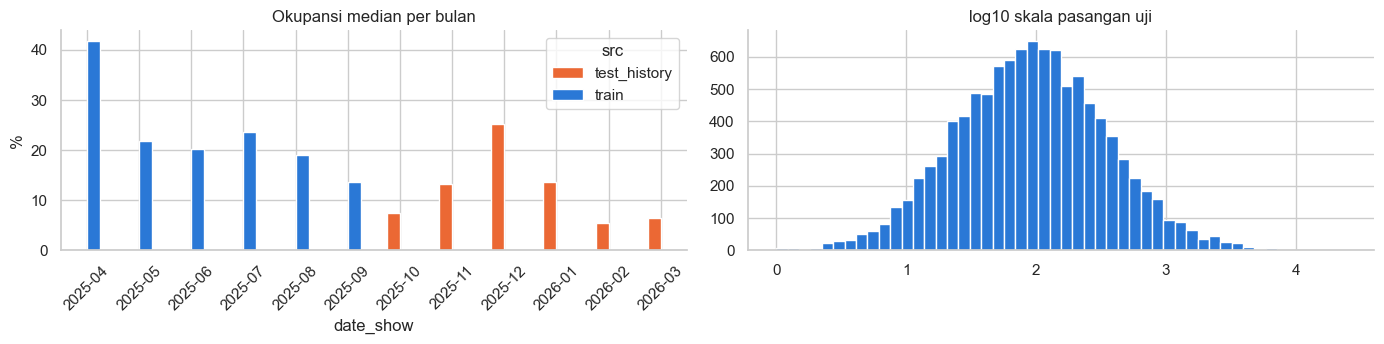

In [13]:
if CFG.RUN_MODE == "END_TO_END":
    occ = pd.concat([train.assign(src='train'), hist.assign(src='test_history')])
    occ_m = occ.groupby([occ.date_show.dt.to_period('M'), 'src']).occupation_rate.median().unstack()
    s_te = (hist.groupby(KEY).total_ticket.sum() / 3).clip(lower=1).reindex(pd.MultiIndex.from_frame(test[KEY].drop_duplicates()))
    bins = CFG.TW_BINS
    print('test pairs by scale bucket:', pd.cut(s_te, bins).value_counts(normalize=True).sort_index().round(3).to_dict())

    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
    occ_m.plot.bar(ax=ax[0], rot=45, color=[PAL[1], PAL[0]]); ax[0].set(title='Okupansi median per bulan', ylabel='%')
    ax[1].hist(np.log10(s_te), bins=50, color=PAL[0]); ax[1].set(title='log10 skala pasangan uji')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'market.png'); plt.show()

#### Insights

> Sekitar 12,9% pasangan uji memiliki skala di bawah 20. Evaluasi rata-rata tanpa rincian skala dapat menyamarkan kegagalan pada pasangan tersebut.

## Kalender: Hari Kerja dan Akhir Pekan

Profil hari dihitung setelah menormalkan penjualan terhadap rata-rata bergerak pasangan. Analisis ini bersifat deskriptif pada train; rata-rata terpusat tidak dimasukkan sebagai fitur prediksi.

weekday multiplier: {'Mon': 0.814, 'Tue': 0.794, 'Wed': 0.811, 'Thu': 0.783, 'Fri': 0.853, 'Sat': 1.32, 'Sun': 1.282}


,name,dow,excess
date_show,,,
2025-04-18,Wafat Yesus Kristus,4,1.54
2025-04-20,Kebangkitan Yesus Kristus (Paskah),6,0.88
2025-05-01,Hari Buruh Internasional,3,1.85
2025-05-12,Hari Raya Waisak 2569 BE,0,1.88
2025-05-29,Kenaikan Yesus Kristus,3,1.98
2025-06-01,Hari Lahir Pancasila,6,0.35
2025-06-06,Idul Adha 1446 H,4,3.08
2025-06-27,1 Muharam Tahun Baru Islam 1447 H,4,1.48
2025-08-17,Proklamasi Kemerdekaan Republik Indonesia,6,1.11


xmas     test rows   5235 (7.2%), films 15
ramadan  test rows  12408 (17.1%), films 37
lebaran  test rows   4417 (6.1%), films 7


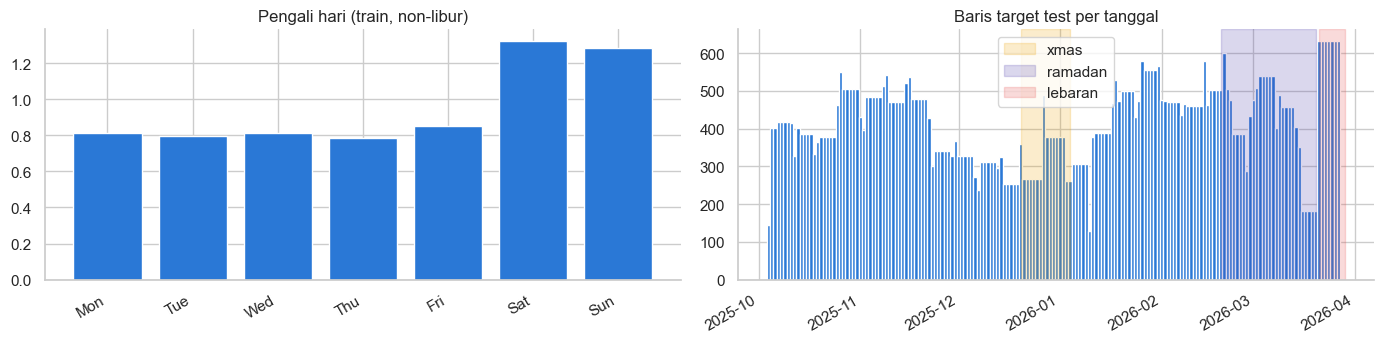

In [14]:
if CFG.RUN_MODE == "END_TO_END":
    DOW = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    x = train.set_index('date_show').groupby(KEY).total_ticket.apply(lambda s: s.asfreq('D', fill_value=0)).reset_index()
    x['m7'] = x.groupby(KEY).total_ticket.transform(lambda s: s.rolling(7, center=True).mean())
    x = x[(x.m7 >= 20) & ~x.date_show.isin(CFG.OUTAGE)].merge(hol, left_on='date_show', right_on='date', how='left')
    x['mult'] = x.total_ticket / x.m7
    day = x.groupby('date_show').agg(mult=('mult', 'median'), hol=('holiday_tipe', 'first'), name=('holiday_name', 'first'))
    day['dow'] = day.index.dayofweek
    prof = day[day.hol == 'normal'].groupby('dow').mult.median()
    day['excess'] = day.mult / day.dow.map(prof)
    print('weekday multiplier:', dict(zip(DOW, prof.round(3))))
    display(day[day.hol == 'holiday'][['name', 'dow', 'excess']].round(2))

    SEGMENTS = {'xmas': ('2025-12-20', '2026-01-04'), 'ramadan': ('2026-02-19', '2026-03-20'), 'lebaran': ('2026-03-21', '2026-03-29')}
    for n, (a, b) in SEGMENTS.items():
        m = test.date_show.between(a, b)
        print(f'{n:8s} test rows {m.sum():6d} ({m.mean():.1%}), films {test[m].movie_title.nunique()}')

    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
    ax[0].bar(DOW, prof.values, color=PAL[0]); ax[0].set(title='Pengali hari (train, non-libur)')
    cnt = test.groupby('date_show').size()
    ax[1].bar(cnt.index, cnt.values, width=1, color=PAL[0])
    for (n, (a, b)), c in zip(SEGMENTS.items(), [PAL[3], PAL[6], PAL[7]]):
        ax[1].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=.2, label=n)
    ax[1].set(title='Baris target test per tanggal'); ax[1].legend()
    fig.autofmt_xdate(); plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'calendar.png'); plt.show()

#### Insights

> Akhir pekan lebih tinggi daripada hari kerja. Pada target uji, 30,4% baris berada di Natal, Ramadan, atau Lebaran; generalisasi kalender perlu dibahas terpisah dari akurasi pada film latih.

## Pembukaan D3 dan Pergeseran Nol

Proxy D1-D2 menuju D3 memakai tiket D3 yang sudah tersedia dalam riwayat resmi. Proxy memberi diagnosis periode pembukaan, bukan evaluasi horizon D4-D10.

,train_share,test_share,train_cv_mase,test_period_mase,train_zero_D3,test_zero_D3
s,,,,,,
"(0.0, 5.0]",0.004,0.024,1.062,1.171,0.771,0.544
"(5.0, 20.0]",0.053,0.134,0.750,0.693,0.568,0.308
"(20.0, 50.0]",0.134,0.208,0.612,0.587,0.392,0.107
"(50.0, 100.0]",0.173,0.195,0.533,0.481,0.129,0.028
"(100.0, 200.0]",0.217,0.185,0.418,0.410,0.031,0.011
"(200.0, 500.0]",0.249,0.160,0.342,0.344,0.004,0.002
"(500.0, 1000000000.0]",0.170,0.093,0.355,0.285,0.002,0.000


proxy MASE: train CV 0.4544 | re-weighted to test scale mix 0.5232 | real test period 0.4950


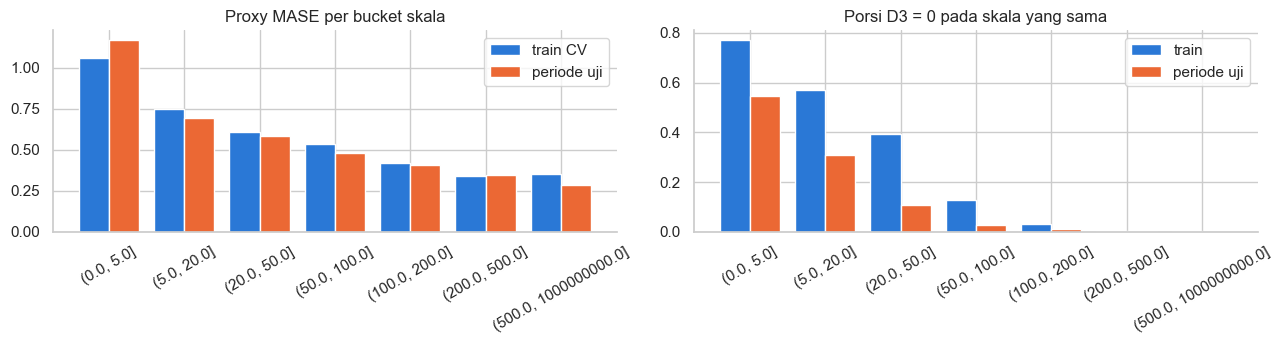

,train_drop_D3,test_drop_D3,train_n,test_n
"(0.226, 7.8]",0.499,0.219,948,3070
"(7.8, 14.833]",0.256,0.063,1393,2605
"(14.833, 25.2]",0.085,0.030,1795,2221
"(25.2, 44.9]",0.023,0.014,2296,1702
"(44.9, 425.167]",0.002,0.005,2531,1476


D3 stop rate by release month: {Period('2025-04', 'M'): 0.082, Period('2025-05', 'M'): 0.13, Period('2025-06', 'M'): 0.173, Period('2025-07', 'M'): 0.083, Period('2025-08', 'M'): 0.137, Period('2025-09', 'M'): 0.096, Period('2025-10', 'M'): 0.096, Period('2025-11', 'M'): 0.08, Period('2025-12', 'M'): 0.062, Period('2026-01', 'M'): 0.081, Period('2026-02', 'M'): 0.107, Period('2026-03', 'M'): 0.066}


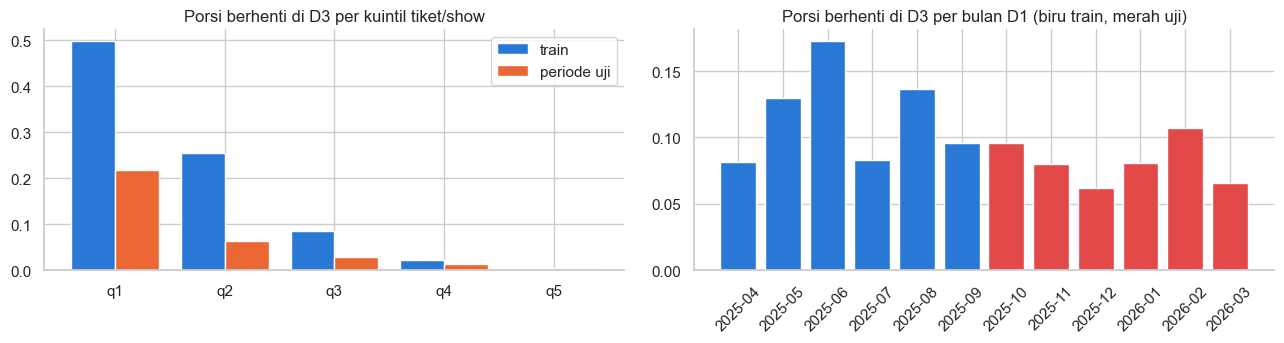

In [15]:
if CFG.RUN_MODE == "END_TO_END":
    def proxy(hh):
        d1 = hh.groupby('movie_title').date_show.min().rename('d1')
        x = hh.join(d1, on='movie_title')
        x['d'] = (x.date_show - x.d1).dt.days + 1
        P = x.pivot_table(index=KEY, columns='d', values='total_ticket', fill_value=0).reindex(columns=[1, 2, 3], fill_value=0)
        S = x.pivot_table(index=KEY, columns='d', values='total_show', fill_value=0).reindex(columns=[1, 2], fill_value=0)
        O = x.pivot_table(index=KEY, columns='d', values='occupation_rate', fill_value=0).reindex(columns=[1, 2], fill_value=0)
        P = P[P[2] > 0]
        f = pd.DataFrame({'s': ((P[1] + P[2]) / 2).clip(lower=1), 'y': P[3]}, index=P.index)
        f['q1'], f['q2'], f['log_s'] = P[1] / f.s, P[2] / f.s, np.log1p(f.s)
        f['sh1'], f['sh2'] = S.reindex(P.index)[1], S.reindex(P.index)[2]
        f['sh_tr'] = (f.sh2 + 1) / (f.sh1 + 1)
        f['occ2'] = O.reindex(P.index)[2]
        f = f.reset_index().join(d1, on='movie_title')
        g = x[x.d <= 2].groupby(['movie_title', 'd']).total_ticket.sum().unstack().reindex(columns=[1, 2], fill_value=0)
        f['f_tr'] = f.movie_title.map((g[2] + 1) / (g[1] + 1))
        f['f_log'] = f.movie_title.map(np.log1p(g.mean(axis=1)))
        f['f_nc'] = f.movie_title.map(x[x.d == 2].groupby('movie_title').cinema_ids.nunique())
        f['d1_dow'] = f.d1.dt.dayofweek
        return f


    PA, PB = proxy(hs), proxy(hist)
    pc = ['q1', 'q2', 'log_s', 'sh_tr', 'f_tr', 'f_log', 'd1_dow']
    pm = dict(objective='l1', n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100, verbose=-1, deterministic=True, force_row_wise=True)
    oofA = np.zeros(len(PA))
    for a, b in GroupKFold(5).split(PA, groups=base_title(PA.movie_title)):
        m = lgb.LGBMRegressor(**pm, random_state=CFG.SEED).fit(PA.iloc[a][pc], PA.y.iloc[a] / PA.s.iloc[a])
        oofA[b] = np.clip(m.predict(PA.iloc[b][pc]), 0, None) * PA.s.values[b]
    m = lgb.LGBMRegressor(**pm, random_state=CFG.SEED).fit(PA[pc], PA.y / PA.s)
    pB = np.clip(m.predict(PB[pc]), 0, None) * PB.s.values
    eA, eB = np.abs(PA.y - oofA) / PA.s, np.abs(PB.y - pB) / PB.s
    cutA, cutB = pd.cut(PA.s, bins), pd.cut(PB.s, bins)
    tab = pd.DataFrame({'train_share': cutA.value_counts(normalize=True), 'test_share': cutB.value_counts(normalize=True),
                        'train_cv_mase': eA.groupby(cutA, observed=False).mean(), 'test_period_mase': eB.groupby(cutB, observed=False).mean(),
                        'train_zero_D3': (PA.y == 0).groupby(cutA, observed=False).mean(), 'test_zero_D3': (PB.y == 0).groupby(cutB, observed=False).mean()}).sort_index()
    display(tab.round(3))
    print(f'proxy MASE: train CV {eA.mean():.4f} | re-weighted to test scale mix {(tab.test_share * tab.train_cv_mase).sum():.4f} | real test period {eB.mean():.4f}')

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    xx = np.arange(len(tab))
    ax[0].bar(xx - .2, tab.train_cv_mase, .4, label='train CV'); ax[0].bar(xx + .2, tab.test_period_mase, .4, label='periode uji')
    ax[0].set_xticks(xx, [str(i) for i in tab.index], rotation=30); ax[0].set(title='Proxy MASE per bucket skala'); ax[0].legend()
    ax[1].bar(xx - .2, tab.train_zero_D3, .4, label='train'); ax[1].bar(xx + .2, tab.test_zero_D3, .4, label='periode uji')
    ax[1].set_xticks(xx, [str(i) for i in tab.index], rotation=30); ax[1].set(title='Porsi D3 = 0 pada skala yang sama'); ax[1].legend()
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'proxy.png'); plt.show()
    DA = PA.assign(z=PA.y == 0, tps=PA.s * 2 / (PA.sh1 + PA.sh2).clip(lower=1))
    DB = PB.assign(z=PB.y == 0, tps=PB.s * 2 / (PB.sh1 + PB.sh2).clip(lower=1))
    q = pd.qcut(pd.concat([DA.tps, DB.tps]), 5)
    qa, qb = q.iloc[:len(DA)].values, q.iloc[len(DA):].values
    tq = pd.DataFrame({'train_drop_D3': DA.z.groupby(qa, observed=False).mean(), 'test_drop_D3': DB.z.groupby(qb, observed=False).mean(),
                       'train_n': pd.Series(qa).value_counts(), 'test_n': pd.Series(qb).value_counts()})
    display(tq.round(3))
    zm = pd.concat([DA.assign(m=DA.d1.dt.to_period('M')), DB.assign(m=DB.d1.dt.to_period('M'))]).groupby('m').z.mean()
    print('D3 stop rate by release month:', zm.round(3).to_dict())

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    xx = np.arange(len(tq))
    ax[0].bar(xx - .2, tq.train_drop_D3, .4, label='train'); ax[0].bar(xx + .2, tq.test_drop_D3, .4, label='periode uji')
    ax[0].set_xticks(xx, [f'q{i + 1}' for i in xx]); ax[0].set(title='Porsi berhenti di D3 per kuintil tiket/show'); ax[0].legend()
    ax[1].bar(zm.index.astype(str), zm.values, color=[PAL[0] if str(m) < '2025-10' else PAL[7] for m in zm.index])
    ax[1].set(title='Porsi berhenti di D3 per bulan D1 (biru train, merah uji)'); ax[1].tick_params(axis='x', rotation=45)
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'pull_policy.png'); plt.show()

#### Insights

> Perbedaan proporsi nol D3 memberi alasan menguji offset probabilitas. Hubungan antara pergeseran D3 dan horizon berikutnya merupakan asumsi; setengah offset dipertahankan sebagai konfigurasi final.

---

# Data Cleaning dan Pembentukan Sampel <a name="5"></a>

---

Pembersihan diarahkan pada hari pelaporan bermasalah dan pratinjau yang terpisah dari rilis luas. Data asli tidak diubah; hanya sampel hasil simulasi yang difilter.

## Outage Pelaporan dan Pratinjau

Cakupan klaster per hari menunjukkan tanggal pelaporan bermasalah. A MINECRAFT MOVIE menjadi contoh pratinjau 4-6 April yang dipisahkan dari rilis luas 9 April.

dates with no data: [datetime.date(2025, 6, 13)]
dates with < 70% of clusters reporting: {Timestamp('2025-06-07 00:00:00'): 10.0, Timestamp('2025-06-09 00:00:00'): 1.0, Timestamp('2025-06-10 00:00:00'): 67.0, Timestamp('2025-06-11 00:00:00'): 76.0, Timestamp('2025-06-16 00:00:00'): 62.0}
A MINECRAFT MOVIE coverage 1-10 Apr: {Timestamp('2025-04-04 00:00:00'): 55, Timestamp('2025-04-05 00:00:00'): 68, Timestamp('2025-04-06 00:00:00'): 67, Timestamp('2025-04-09 00:00:00'): 93, Timestamp('2025-04-10 00:00:00'): 91}


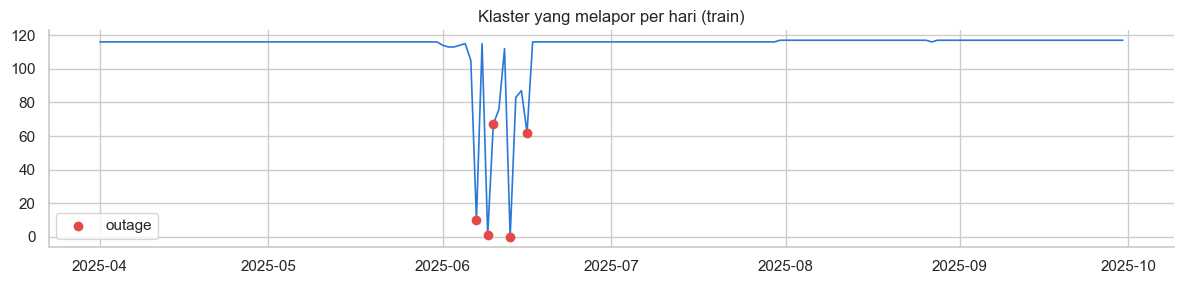

In [16]:
if CFG.RUN_MODE == "END_TO_END":
    rep = train.groupby('date_show').cinema_ids.nunique().reindex(pd.date_range('2025-04-01', CFG.TRAIN_END))
    print('dates with no data:', rep[rep.isna()].index.date.tolist())
    print('dates with < 70% of clusters reporting:', rep[rep < 0.7 * rep.median()].to_dict())
    mc = train[train.movie_title == 'A MINECRAFT MOVIE'].groupby('date_show').cinema_ids.nunique()
    print('A MINECRAFT MOVIE coverage 1-10 Apr:', mc.loc[:'2025-04-10'].to_dict())
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(rep.index, rep.fillna(0), lw=1.2)
    ax.scatter(CFG.OUTAGE, rep.reindex(CFG.OUTAGE).fillna(0), color=PAL[7], zorder=3, label='outage')
    ax.set(title='Klaster yang melapor per hari (train)'); ax.legend()
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'outage.png'); plt.show()

#### Insights

> 13 Juni tidak memiliki transaksi; sejumlah tanggal Juni lainnya memiliki penurunan cakupan tajam. Daftar outage yang dibekukan pada pipeline sumber dipertahankan, tanpa mengubah aturan berdasarkan hasil notebook ini.

## Aturan D1 dan Zero-fill

D1 dipilih dalam segmen kontinu yang memuat puncak cakupan, pada tanggal pertama dengan minimal separuh cakupan puncak dan sedikitnya 25 klaster. Pasangan dipilih dari D3; target hari tanpa transaksi diisi nol setelah hari bermasalah dikeluarkan.

In [17]:
if CFG.RUN_MODE == "END_TO_END":
    dd = pd.date_range('2025-05-01', periods=12)
    toy = pd.DataFrame({'date_show': list(dd) + [dd[0], dd[1]], 'cinema_ids': ['A'] * 12 + ['B', 'B'], 'city_name': 'X',
                        'movie_title': 'M', 'total_ticket': list(range(1, 13)) + [5, 5], 'occupation_rate': 1.0,
                        'total_show': 1}).drop(index=5)
    th_, tg_ = simulate(toy, pd.Series({'M': dd[0]}, name='d1'), bad=pd.DatetimeIndex([]))
    assert set(tg_.cinema_ids) == {'A'} and tg_.total_ticket.tolist() == [4, 5, 0, 7, 8, 9, 10]
    assert np.isclose(pair_scale(th_)[('M', 'B')], 10 / 3)
    print('simulate() self-check passed')

simulate() self-check passed


#### Insights

> 143 judul menghasilkan 56.372 baris evaluasi. Sebanyak 1.435 baris dari 36 judul rilis terbatas ditambahkan hanya pada latih; judul dasar dan varian format tetap dikelompokkan dalam validasi.

---

# Feature Engineering dan Distribusi Input <a name="6"></a>

---

Representasi memisahkan besar pasangan, bentuk kurva, konteks film, kalender, dan profil bioskop. Seluruh urutan fitur dijaga sama dengan pipeline yang menghasilkan submission acuan.

## Kelompok Fitur dan Fungsi

| Kelompok | Contoh | Alasan |
|---|---|---|
| Pembukaan pasangan | `p1`, `p2`, `p3`, `sh_trend`, `n_hist` | pertumbuhan dan kontinuitas D1-D3 |
| Pembukaan film | `fp1`, `fp3`, `f_nc_trend`, `fmt_share` | sinyal lintas klaster dan format |
| Kalender | `dow`, `cal_mult`, `hol_in_hist` | memisahkan kalender dari kurva umur film |
| Kompetisi jadwal | `c_new_n`, `c_new_sh_vs_own` | film baru yang berbagi klaster pada tanggal target |
| Kapasitas relatif | `occ3_r`, `seats`, `cap3_s_r` | posisi pembukaan terhadap minggu rilis |
| Level pasar | `pair_vs_mkt`, `film_pc_vs_mkt` | pembanding pembukaan film 28 hari sebelumnya |
| Profil bioskop | `cin_dowrel`, `cin_wkamp` | variasi respons akhir pekan per bioskop |

Judul dan ID tidak dimasukkan sebagai fitur model. Profil OOF bioskop dihitung ulang setelah seluruh film fold validasi dikeluarkan.

## Normalisasi Minggu Rilis

Median fitur relatif dibandingkan dengan fitur absolut. Nilai okupansi dan kapasitas relatif dihitung hanya dari pembukaan di tiap split, tanpa memakai target D4-D10.

,latih,pembukaan uji
occ3,22.470,12.360
occ3_r,0.000,0.000
cap3_s,1.662,2.177
cap3_s_r,0.000,0.000


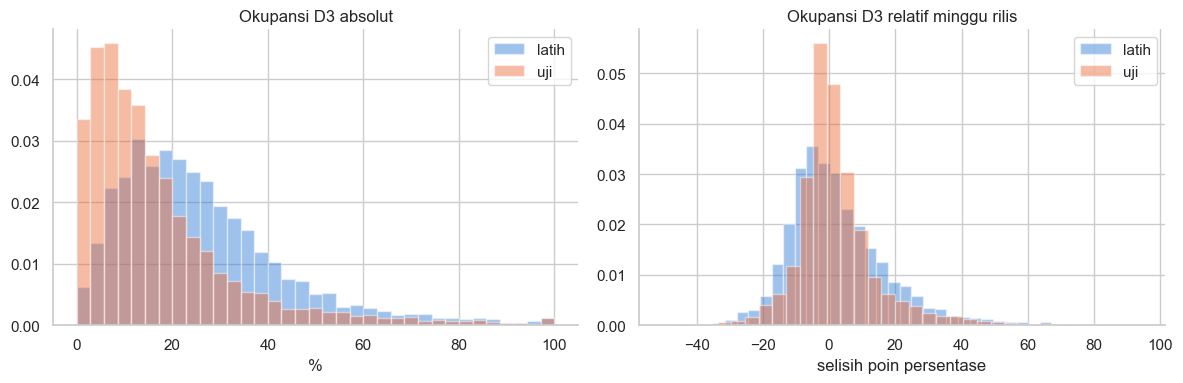

In [18]:
if CFG.RUN_MODE == "END_TO_END":
    display(pd.DataFrame({'latih': Xtr[['occ3','occ3_r','cap3_s','cap3_s_r']].median(),
                          'pembukaan uji': Xte[['occ3','occ3_r','cap3_s','cap3_s_r']].median()}).round(3))
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    for df, label in [(Xtr.drop_duplicates(KEY),'latih'),(Xte.drop_duplicates(KEY),'uji')]:
        axes[0].hist(df.occ3, bins=35, density=True, alpha=.45, label=label)
        axes[1].hist(df.occ3_r, bins=35, density=True, alpha=.45, label=label)
    axes[0].set(title='Okupansi D3 absolut', xlabel='%')
    axes[1].set(title='Okupansi D3 relatif minggu rilis', xlabel='selisih poin persentase')
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'relative_features.png'); plt.show()

#### Insights

> Median okupansi absolut berpindah dari 22,47 ke 12,36. Median versi relatif mendekati nol pada kedua split karena konstruksinya; pemusatan ini belum membuktikan kesamaan distribusi atau performa.

## Profil Hari per Bioskop

Amplitudo akhir pekan merupakan median deviasi log tiket pada minggu lengkap non-libur. Profil bioskop dengan kurang dari empat minggu menggunakan profil nasional.

,amplitudo_log
count,117.000000
mean,0.426734
std,0.251810
min,-0.172047
10%,0.126838
50%,0.397791
90%,0.709539
max,1.335511


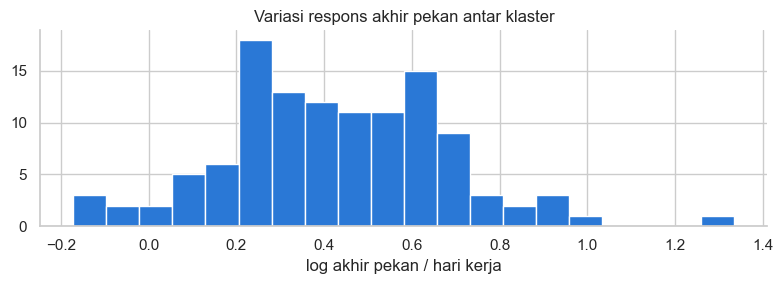

In [19]:
if CFG.RUN_MODE == "END_TO_END":
    amp=(P_all[[5,6]].mean(1)-P_all[[0,1,2,3]].mean(1))
    display(amp.describe(percentiles=[.1,.5,.9]).to_frame('amplitudo_log'))
    fig, ax=plt.subplots(figsize=(8,3)); ax.hist(amp,bins=20)
    ax.set(title='Variasi respons akhir pekan antar klaster',xlabel='log akhir pekan / hari kerja')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'cinema_profile.png'); plt.show()

#### Insights

> Median amplitudo log sekitar 0,40, dengan rentang p10-p90 sekitar 0,13-0,71. Satu pengali hari nasional tidak menangkap semua variasi klaster.

## Adversarial Validation

Classifier membedakan input simulasi latih dari input uji dengan grouping film. AUC merupakan ukuran keterpisahan input, bukan ukuran ketepatan prediksi tiket.

In [20]:
if CFG.RUN_MODE == "END_TO_END":
    def adv_auc(cols):
        A = pd.concat([Xtr[cols].assign(t=0, g=Xtr.movie_title), Xte[cols].assign(t=1, g=Xte.movie_title)], ignore_index=True)
        oof = np.zeros(len(A))
        for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=CFG.SEED).split(A, A.t, A.g):
            m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=CFG.SEED, verbose=-1)
            oof[b] = m.fit(A.iloc[a][cols], A.t.iloc[a]).predict_proba(A.iloc[b][cols])[:, 1]
        return roc_auc_score(A.t, oof)


    shape_cols = ['p1', 'p2', 'p3', 'fp1', 'fp3', 'share', 'sh_trend', 'd1_dow', 'n_hist']
    print(f"AUC shape features only:         {adv_auc(shape_cols):.3f}")
    print(f"AUC + absolute level (log_s, f_logT): {adv_auc(shape_cols + ['log_s', 'f_logT']):.3f}")
    print(f"AUC + market-relative level:     {adv_auc(shape_cols + ['pair_vs_mkt', 'film_pc_vs_mkt']):.3f}")

AUC shape features only:         0.510


AUC + absolute level (log_s, f_logT): 0.544


AUC + market-relative level:     0.479


#### Insights

> AUC fitur bentuk kurva dekat 0,5 pada run sumber. Perbandingan level absolut dan relatif digunakan sebagai diagnosis drift; nilai rendah tidak menghilangkan risiko perubahan hubungan fitur-target.

---

# Strategi Validasi dan Baseline <a name="7"></a>

---

Validasi memakai lima fold atas judul dasar film, dengan pemetaan deterministik dari urutan judul dan seed 2026. Skema aktual ini dipertahankan, bukan diganti menjadi split acak per baris atau stratifikasi baru.

## Fold dan Audit Grouping

Setiap varian 2D, 3D, dan IMAX dari judul dasar yang sama mempunyai fold yang sama. Tabel menunjukkan jumlah baris serta judul dasar per fold.

In [21]:
if CFG.RUN_MODE == "END_TO_END":
    fold_table=pd.DataFrame({'fold':FOLD,'base':base_title(Xtr.movie_title),'rows':1}).groupby('fold').agg(rows=('rows','sum'),films=('base','nunique'))
    display(fold_table)
    for k in range(CFG.N_FOLDS):
        a=set(base_title(Xtr.movie_title[FOLD!=k])); b=set(base_title(Xtr.movie_title[FOLD==k]))
        assert a.isdisjoint(b)
        assert set(base_title(Xlim.movie_title)).isdisjoint(b)
    print('Grouping checks passed')

,rows,films
fold,,
0,12845,26
1,10508,25
2,11389,25
3,11620,25
4,10010,25


Grouping checks passed


#### Insights

> Profil hari bioskop dihitung per fold dengan film validasi dikeluarkan. Namun ukuran bioskop (`cin_size`) dan statistik jumlah film/show pada pipeline acuan dihitung dari seluruh transaksi train. OOF ini karena itu berbagi statistik agregat antar-fold dan bukan evaluasi yang seluruh transformasinya fit hanya pada fold latih. Batas ini dipertahankan untuk reproduksi konfigurasi acuan; skor OOF tidak dibaca sebagai bukti temporal ketat.

## Baseline Nol dan Median Kalender

Baseline nol dan median rasio per horizon serta hari rilis dinilai pada fold yang sama. Baseline median hanya memakai target fold latih.

In [22]:
if CFG.RUN_MODE == "END_TO_END":
    results = []
    rc = y / s / cm
    oof_base = np.zeros(len(Xtr))
    for k in range(CFG.N_FOLDS):
        a, b = FOLD != k, FOLD == k
        med = pd.Series(rc[a]).groupby([hh_[a], Xtr.d1_dow.values[a]]).median()
        oof_base[b] = med.reindex(pd.MultiIndex.from_arrays([hh_[b], Xtr.d1_dow.values[b]])).fillna(np.median(rc[a])).values * cm[b] * s[b]
    results.append(score(np.zeros(len(Xtr)), 'zero'))
    results.append(score(oof_base, 'median r/c by (h, D1 dow)'))

zero                                     MASE 0.5881 | TW-MASE 0.5394 (old 0.6104) | s<=20 0.8820 | s>200 0.6309
median r/c by (h, D1 dow)                MASE 0.4002 | TW-MASE 0.4330 (old 0.4951) | s<=20 0.9822 | s>200 0.3279


#### Insights

> Run sumber menghasilkan MASE sekitar 0,588 untuk nol dan 0,400 untuk median kalender. Pembanding sederhana ini memisahkan manfaat model dari manfaat skala dan kalender saja.

---

# Modeling: LightGBM dan TabPFN <a name="8"></a>

---

Dua keluarga model diuji pada fold identik. Hyperparameter serta bobot final dibekukan sebelum notebook dijalankan; tabel evaluasi memberi diagnosis dan tidak mengubah konfigurasi otomatis.

## LightGBM: Median, Nol, dan Kuantil Positif

Regresi L1 memakai bobot `cal_mult`. Klasifier nol ditambah fitur kompetisi bioskop, lalu 19 kuantil dipelajari dari target positif. Prediksi hurdle memiliki bobot 0,75 dalam komponen LightGBM.

In [23]:
if CFG.RUN_MODE == "END_TO_END":
    t0 = time.time()
    oof_l1, oof_p0, oof_Q = np.zeros(len(Xtr)), np.zeros(len(Xtr)), np.zeros((len(Xtr), len(CFG.QS)))
    for k in range(CFG.N_FOLDS):
        v = FOLD == k
        P_k, g_k = fold_profile(k)
        oof_l1[v], oof_p0[v], oof_Q[v] = predict_lgb_all(fit_lgb_all(train_part(k), P_k, g_k), Xtr[v], P_k, g_k)
        print(f'fold {k} done ({time.time() - t0:.0f}s)')
    results.append(score(oof_l1 * cm * s, 'LightGBM L1'))
    results.append(score(mixture_median(oof_p0, oof_Q, CFG.QS, 0.0) * cm * s, 'LightGBM hurdle (lambda 0)'))

fold 0 done (24s)


fold 1 done (49s)


fold 2 done (73s)


fold 3 done (97s)


fold 4 done (121s)
LightGBM L1                              MASE 0.3217 | TW-MASE 0.3476 (old 0.4091) | s<=20 0.8932 | s>200 0.2633
LightGBM hurdle (lambda 0)               MASE 0.3043 | TW-MASE 0.3221 (old 0.3817) | s<=20 0.8167 | s>200 0.2553


## Analisis Skenario Pergeseran

Target sintetis pada sel ini hanya analisis sensitivitas: sebagian target nol diganti sampel kuantil OOF menurut skenario pergeseran. Tidak ada fitting model pada target sintetis. MASE resmi tetap memakai target transaksi latih.

zero rate: real 0.300 | shifted world 0.245


,lam,w,real,shifted,regret_real,regret_shifted,max_regret
4,0.0,1.00,0.3221,0.3420,0.0000,0.0035,0.0035
3,0.0,0.75,0.3266,0.3444,0.0046,0.0059,0.0059
9,0.5,1.00,0.3279,0.3384,0.0059,0.0000,0.0059
8,0.5,0.75,0.3309,0.3416,0.0088,0.0031,0.0088
2,0.0,0.50,0.3324,0.3481,0.0104,0.0096,0.0104
7,0.5,0.50,0.3352,0.3462,0.0131,0.0077,0.0131
1,0.0,0.25,0.3394,0.3531,0.0173,0.0147,0.0173
13,1.0,0.75,0.3397,0.3431,0.0176,0.0047,0.0176


chosen in Settings: HURDLE_W=0.75, LAMBDA=0.5
LightGBM mix (hurdle w, lambda)          MASE 0.3099 | TW-MASE 0.3309 (old 0.3907) | s<=20 0.8412 | s>200 0.2567


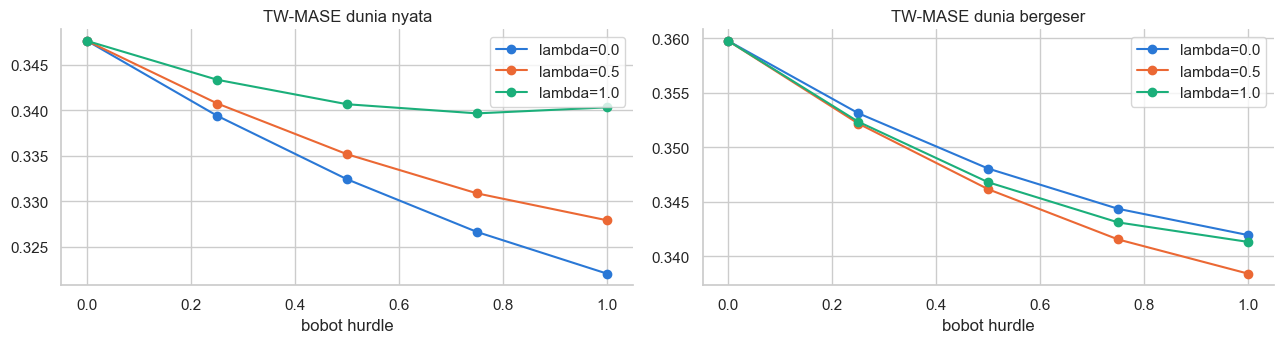

In [24]:
if CFG.RUN_MODE == "END_TO_END":
    rng = np.random.default_rng(CFG.SEED)
    p_sh = sigm(logit(np.clip(oof_p0, 1e-4, 1 - 1e-4)) + CFG.KAPPA * PULL_A)
    unpull = (y == 0) & (rng.random(len(y)) < 1 - p_sh / np.clip(oof_p0, 1e-6, None))
    draw = np.array([np.interp(u, CFG.QS, q) for u, q in zip(rng.random(len(y)), oof_Q)])
    y_shift = np.where(unpull, np.clip(draw, 0, None) * cm * s, y)
    print(f'zero rate: real {np.mean(y == 0):.3f} | shifted world {np.mean(y_shift == 0):.3f}')

    twm = lambda yy, pr: np.average(np.abs(yy - pr) / s, weights=TW)
    rows = []
    for lam in (0.0, 0.5, 1.0):
        hu = mixture_median(oof_p0, oof_Q, CFG.QS, lam)
        for w in (0.0, 0.25, 0.5, 0.75, 1.0):
            pr = ((1 - w) * oof_l1 + w * hu) * cm * s
            rows.append(dict(lam=lam, w=w, real=twm(y, pr), shifted=twm(y_shift, pr)))
    D = pd.DataFrame(rows)
    for c in ('real', 'shifted'):
        D[f'regret_{c}'] = D[c] - D[c].min()
    D['max_regret'] = D[['regret_real', 'regret_shifted']].max(axis=1)
    display(D.round(4).sort_values('max_regret').head(8))
    print(f'chosen in Settings: HURDLE_W={CFG.HURDLE_W}, LAMBDA={CFG.LAMBDA}')
    oof_lgbmix = ((1 - CFG.HURDLE_W) * oof_l1 + CFG.HURDLE_W * mixture_median(oof_p0, oof_Q, CFG.QS, CFG.LAMBDA)) * cm * s
    results.append(score(oof_lgbmix, 'LightGBM mix (hurdle w, lambda)'))

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    for lam, g in D.groupby('lam'):
        ax[0].plot(g.w, g.real, marker='o', label=f'lambda={lam}')
        ax[1].plot(g.w, g.shifted, marker='o', label=f'lambda={lam}')
    ax[0].set(title='TW-MASE dunia nyata', xlabel='bobot hurdle'); ax[1].set(title='TW-MASE dunia bergeser', xlabel='bobot hurdle')
    ax[0].legend(); ax[1].legend()
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'decision.png'); plt.show()

#### Insights

> Kinerja terhadap skenario bergeser harus dibaca sebagai stress test berbasis asumsi. Nilainya tidak disamakan dengan skor kompetisi.

## TabPFN per Horizon

Tujuh model in-context memakai masing-masing data horizon D4-D10. Sebanyak 75 fitur dengan dtype float32 dan urutan tetap dimasukkan ke konteks; 49 kuantil dibaca dengan batch 3.000 baris.

In [25]:
if CFG.RUN_MODE == "END_TO_END":
    oof_tabQ = None
    if CFG.USE_TABPFN:
        t0 = time.time()
        oof_tabQ = np.zeros((len(Xtr), len(CFG.TAB_QS)))
        for k in range(CFG.N_FOLDS):
            P_k, g_k = fold_profile(k)
            oof_tabQ[FOLD == k] = tabpfn_quantiles(add_dow(train_part(k), P_k, g_k), add_dow(Xtr[FOLD == k], P_k, g_k))
            print(f'fold {k} done ({time.time() - t0:.0f}s)')
        results.append(score(tabpfn_median(oof_tabQ, 0.0) * cm * s, 'TabPFN-3.5 median (lambda 0)'))
        results.append(score(tabpfn_median(oof_tabQ, CFG.LAMBDA) * cm * s, 'TabPFN-3.5 median (lambda)'))

fold 0 done (76s)


fold 1 done (150s)


fold 2 done (224s)


fold 3 done (297s)


fold 4 done (372s)
TabPFN-3.5 median (lambda 0)             MASE 0.2972 | TW-MASE 0.3144 (old 0.3728) | s<=20 0.7967 | s>200 0.2499


TabPFN-3.5 median (lambda)               MASE 0.2988 | TW-MASE 0.3165 (old 0.3750) | s<=20 0.8055 | s>200 0.2515


## Perbandingan Komponen dan Blend

Bobot akhir 0,2 dan 0,8 dipertahankan dari konfigurasi submission acuan. Grid bobot ditampilkan sebagai sensitivitas OOF, bukan pemilihan ulang. Sel ini juga menampilkan korelasi error bertanda.

In [26]:
if CFG.RUN_MODE == "END_TO_END":
    COMP = {'lgb': oof_lgbmix}
    if oof_tabQ is not None:
        COMP['tabpfn'] = tabpfn_median(oof_tabQ, CFG.LAMBDA) * cm * s
    names = list(COMP)
    grid = np.round(np.arange(0, 1.01, 0.1), 1)
    cands = [w for w in itertools.product(grid, repeat=len(names)) if abs(sum(w) - 1) < 1e-9]
    rows = []
    for w in cands:
        pr = sum(wi * COMP[n] for wi, n in zip(w, names))
        rows.append(dict(zip([f'w_{n}' for n in names], w), real=twm(y, pr), kappa=twm(y_shift, pr)))
    BW = pd.DataFrame(rows).sort_values('kappa')
    display(BW.head(8).round(4))
    print('bobot terbaik grid dunia kappa (informasi):', {n: float(BW.iloc[0][f'w_{n}']) for n in names})
    WEIGHTS = CFG.WEIGHTS  # 0,4 / 0,6: terbaik di lensa out-of-time dan setara v10a; lensa pergeseran memilih TabPFN lebih besar
    oof_final = sum(WEIGHTS[n] * COMP[n] for n in names)
    print('chosen weights:', WEIGHTS)
    err = pd.DataFrame({n: (y - COMP[n]) / s for n in names})
    print('signed-error correlation:\n', err.corr().round(3))
    results.append(score(oof_final, 'final blend'))
    results.append(score(oof_final, 'final blend, kappa=0.5 world', yy=y_shift))
    display(pd.DataFrame(results).set_index('model').round(4))

,w_lgb,w_tabpfn,real,kappa
3,0.3,0.7,0.3185,0.3355
4,0.4,0.6,0.3196,0.3356
2,0.2,0.8,0.3177,0.3358
5,0.5,0.5,0.3209,0.3359
1,0.1,0.9,0.3170,0.3362
6,0.6,0.4,0.3224,0.3364
0,0.0,1.0,0.3165,0.3369
7,0.7,0.3,0.3242,0.3372


bobot terbaik grid dunia kappa (informasi): {'lgb': 0.3, 'tabpfn': 0.7}
chosen weights: {'lgb': 0.2, 'tabpfn': 0.8}
signed-error correlation:
           lgb  tabpfn
lgb     1.000   0.986
tabpfn  0.986   1.000
final blend                              MASE 0.2992 | TW-MASE 0.3177 (old 0.3763) | s<=20 0.8109 | s>200 0.2505
final blend, kappa=0.5 world             MASE 0.3068 | TW-MASE 0.3358 (old 0.3999) | s<=20 0.9248 | s>200 0.2464


,MASE,TW_MASE,TW_OLD,small,big
model,,,,,
zero,0.5881,0.5394,0.6104,0.8820,0.6309
"median r/c by (h, D1 dow)",0.4002,0.4330,0.4951,0.9822,0.3279
LightGBM L1,0.3217,0.3476,0.4091,0.8932,0.2633
LightGBM hurdle (lambda 0),0.3043,0.3221,0.3817,0.8167,0.2553
"LightGBM mix (hurdle w, lambda)",0.3099,0.3309,0.3907,0.8412,0.2567
TabPFN-3.5 median (lambda 0),0.2972,0.3144,0.3728,0.7967,0.2499
TabPFN-3.5 median (lambda),0.2988,0.3165,0.3750,0.8055,0.2515
final blend,0.2992,0.3177,0.3763,0.8109,0.2505
"final blend, kappa=0.5 world",0.3068,0.3358,0.3999,0.9248,0.2464


#### Insights

> Run sumber: MASE resmi blend sekitar 0,2992 dan TW-MASE sekitar 0,3177. TabPFN tanpa offset memiliki MASE OOF sedikit lebih rendah; pemilihan sistem final juga membawa asumsi perubahan periode dan kalender.

---

# Evaluation dan Analisis Error <a name="9"></a>

---

Analisis error hanya menggunakan prediksi out-of-fold pada sampel latih. Tabel per horizon, skala, judul, dan hari penayangan memperlihatkan lokasi kesalahan serta kontribusinya terhadap MASE.

## Overall dan Per Fold

MASE dan TW-MASE dihitung terpisah per fold; ukuran sampel dan dispersi fold dicetak. Baris bukan unit independen, sehingga interval ketidakpastian berikutnya melakukan resampling judul dasar.

In [27]:
if CFG.RUN_MODE == "END_TO_END":
    E=Xtr[['movie_title','cinema_ids','date_show','h','scale','total_ticket','d1_dow','dow']].copy()
    E['pred']=oof_final; E['fold']=FOLD; E['base']=base_title(E.movie_title)
    E['error']=(E.pred-E.total_ticket)/E.scale; E['ae']=E.error.abs(); E['tw']=TW
    fold_scores=E.groupby('fold').apply(lambda g: pd.Series({'rows':len(g),'MASE':g.ae.mean(),'TW_MASE':np.average(g.ae,weights=g.tw)}),include_groups=False)
    display(fold_scores.round(5)); print('mean/std across folds:',fold_scores.MASE.mean(),fold_scores.MASE.std())
    g=E.groupby('base').agg(loss=('ae','sum'),n=('ae','size'))
    rng=np.random.default_rng(CFG.XAI_SEED)
    samples=rng.integers(0,len(g),size=(1000,len(g)))
    boot=g.loss.values[samples].sum(1)/g.n.values[samples].sum(1)
    print('Film-bootstrap MASE interval 95%:',np.quantile(boot,[.025,.975]))
    E.to_csv(CFG.OUTPUT_DIR/'oof_diagnostics.csv',index=False)
    fold_scores.to_csv(CFG.OUTPUT_DIR/'fold_scores.csv')

,rows,MASE,TW_MASE
fold,,,
0,12845.0,0.36969,0.38587
1,10508.0,0.28786,0.30833
2,11389.0,0.30267,0.33880
3,11620.0,0.31949,0.37768
4,10010.0,0.19293,0.19030


mean/std across folds: 0.29452831176820193 0.06462443557450177
Film-bootstrap MASE interval 95%: [0.2492981  0.36160217]


#### Insights

> Interval resampling film mengukur variasi pada kumpulan film evaluasi ini. Interval tersebut tidak mencakup seluruh risiko kalender baru atau perubahan periode.

## Segmen Skala dan Horizon

Galat dibedah menurut skala, horizon, dan hari penayangan. Kontribusi pada MASE aktual dihitung dari jumlah galat tiap segmen dibagi jumlah baris keseluruhan.

,rows,MASE,error_sum,zero_rate,contribution
bucket,,,,,
"(0.0, 5.0]",161,2.5669,413.2706,0.7578,0.0073
"(5.0, 20.0]",1643,0.6388,1049.5616,0.7608,0.0186
"(20.0, 50.0]",5689,0.3922,2230.9606,0.6224,0.0396
"(50.0, 100.0]",9499,0.3083,2928.8412,0.5201,0.0520
"(100.0, 200.0]",13262,0.2789,3698.5728,0.3328,0.0656
"(200.0, 500.0]",15541,0.2690,4179.9546,0.1506,0.0741
"(500.0, 1000000000.0]",10577,0.2234,2363.1679,0.0263,0.0419


,MASE,bias,rows
h,,,
4,0.3275,-0.0828,8015
5,0.3491,-0.0928,8113
6,0.2825,-0.0879,8015
7,0.2836,-0.0965,8015
8,0.2712,-0.0773,8113
9,0.2831,-0.0987,8113
10,0.2971,-0.1054,7988


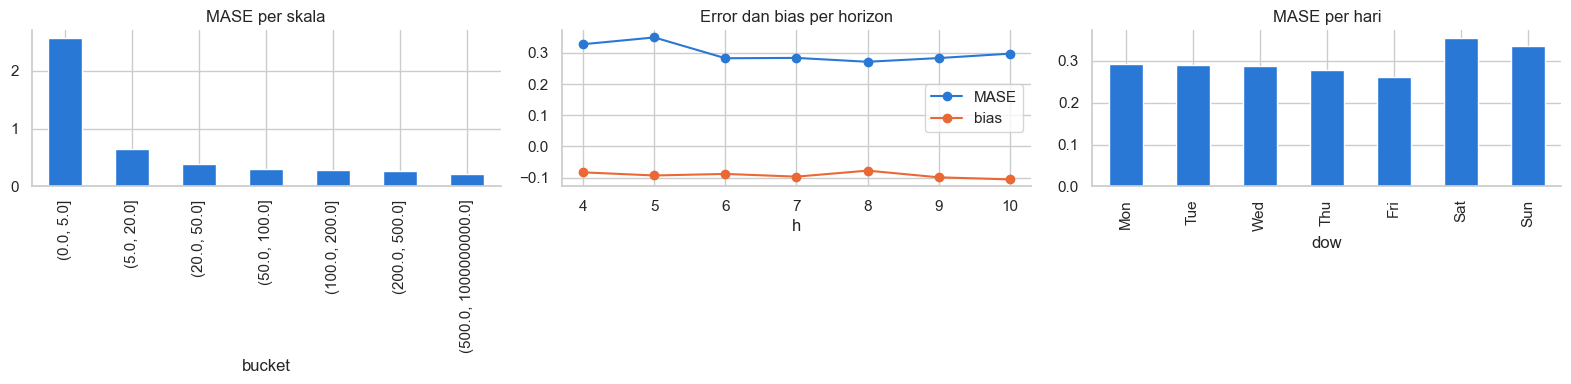

In [28]:
if CFG.RUN_MODE == "END_TO_END":
    E['bucket']=pd.cut(E.scale,CFG.TW_BINS)
    scale_error=E.groupby('bucket',observed=False).agg(rows=('ae','size'),MASE=('ae','mean'),error_sum=('ae','sum'),zero_rate=('total_ticket',lambda v:(v==0).mean()))
    scale_error['contribution']=scale_error.error_sum/len(E)
    display(scale_error.round(4))
    by_h=E.groupby('h').agg(MASE=('ae','mean'),bias=('error','mean'),rows=('ae','size'))
    display(by_h.round(4))
    fig,ax=plt.subplots(1,3,figsize=(16,4))
    scale_error.MASE.plot.bar(ax=ax[0]); ax[0].set_title('MASE per skala')
    by_h[['MASE','bias']].plot(ax=ax[1],marker='o'); ax[1].set_title('Error dan bias per horizon')
    E.groupby('dow').ae.mean().plot.bar(ax=ax[2]); ax[2].set_xticks(range(7),DOW); ax[2].set_title('MASE per hari')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'error_segments.png'); plt.show()

#### Insights

> Skala terkecil memiliki error relatif tertinggi. Horizon D4 dan D5 lebih sulit pada run sumber; efek ini perlu dipisahkan dari komposisi hari rilis dan akhir pekan.

## Film dengan Error Terbesar

Pemeringkatan menampilkan MASE serta kontribusi total. Plot mengambil tiga film dengan kontribusi terbesar dan membandingkan lintasan agregat OOF terhadap penjualan latih.

,rows,MASE,error_sum,tickets,pred,contribution
movie_title,,,,,,
SORE ISTRI DARI MASA DEPAN,609,2.088,1271.749,657472.0,254049.993,0.023
SAYAP SAYAP PATAH 2: OLIVIA,651,1.205,784.399,124218.0,41974.843,0.014
LILO & STITCH,777,1.009,783.670,286048.0,163918.607,0.014
UNTIL DAWN,406,1.404,570.104,49732.0,34855.353,0.010
WEAPONS,693,0.605,419.162,313301.0,184289.328,0.007
THE SHADOWS EDGE,756,0.482,364.408,276781.0,214328.469,0.006
EJEN ALI: THE MOVIE 2,490,0.577,282.798,78063.0,41959.574,0.005
PENGEPUNGAN DI BUKIT DURI,546,0.489,266.729,448019.0,246673.746,0.005
THE CONJURING: LAST RITES,819,0.320,261.747,1010177.0,1643979.703,0.005


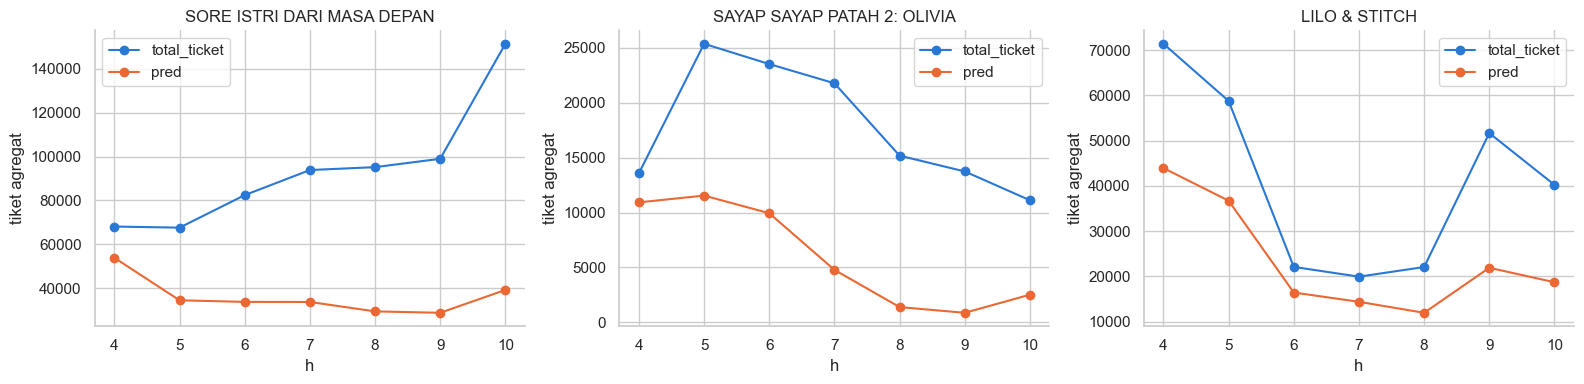

In [29]:
if CFG.RUN_MODE == "END_TO_END":
    film_error=E.groupby('movie_title').agg(rows=('ae','size'),MASE=('ae','mean'),error_sum=('ae','sum'),tickets=('total_ticket','sum'),pred=('pred','sum'))
    film_error['contribution']=film_error.error_sum/len(E)
    display(film_error.sort_values('contribution',ascending=False).head(10).round(3))
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,title in zip(axes,film_error.contribution.nlargest(3).index):
        f=E[E.movie_title==title].groupby('h')[['total_ticket','pred']].sum()
        f.plot(ax=ax,marker='o'); ax.set(title=title, ylabel='tiket agregat')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'film_errors.png'); plt.show()

#### Insights

> Error yang bergerak serentak lintas klaster dapat berasal dari perubahan permintaan tingkat film. Pola OOF mendukung diagnosis ini tetapi tidak membuktikan penyebab seperti word-of-mouth.

## Komponen: Kapan Blend Membantu?

Perbandingan dihitung pada baris yang sama. Korelasi error tinggi berarti sebagian besar kegagalan bersama; manfaat blend harus diperiksa per fold dan segmen.

In [30]:
if CFG.RUN_MODE == "END_TO_END":
    diagnostic=[]
    for name,p in COMP.items():
        for k in range(CFG.N_FOLDS):
            v=FOLD==k
            diagnostic.append({'model':name,'fold':k,'MASE':mase(y[v],p[v],s[v])})
    display(pd.DataFrame(diagnostic).pivot(index='fold',columns='model',values='MASE').round(5))
    display(pd.DataFrame({n:(p-y)/s for n,p in COMP.items()}).corr().round(4))

model,lgb,tabpfn
fold,,
0,0.36779,0.37239
1,0.29405,0.28784
2,0.32049,0.30061
3,0.33713,0.31861
4,0.20838,0.19104


,lgb,tabpfn
lgb,1.000,0.986
tabpfn,0.986,1.000


#### Insights

> Blend menambah kompleksitas dan tidak menjamin perbaikan pada setiap fold. Konfigurasi final dijelaskan sebagai pilihan yang dikunci, sementara tabel ini tetap menampilkan pembanding yang lebih baik jika ada.

---

# Explainable AI <a name="10"></a>

---

Penjelasan model memisahkan kontribusi internal LightGBM, respons prediksi terhadap satu fitur, dan pengaruh aturan kalender. Penjelasan fitur tidak ditafsirkan sebagai efek kausal terhadap penjualan.

## TreeSHAP pada Komponen LightGBM

Kontribusi dihitung dari model fold 0 pada film yang tidak dipakai untuk fitting. `pred_contrib=True` memakai TreeSHAP bawaan LightGBM. Untuk klasifier nol, kontribusi berada pada skala raw log-odds; untuk regresi L1, pada skala rasio tiket.

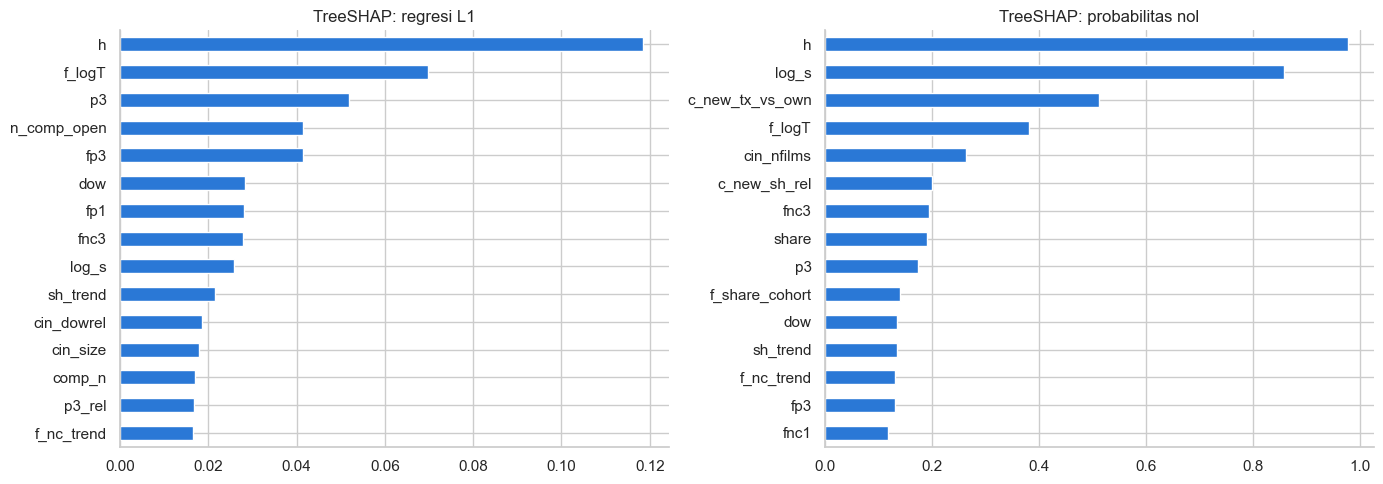

,mean_abs_contribution
h,0.1184
f_logT,0.0697
p3,0.0519
n_comp_open,0.0414
fp3,0.0414
dow,0.0284
fp1,0.0281
fnc3,0.0278
log_s,0.0257
sh_trend,0.0214


In [31]:
if CFG.RUN_MODE == "END_TO_END":
    P0,g0=fold_profile(0)
    xai_fit=fit_lgb_all(train_part(0),P0,g0)
    xai_val=add_dow(Xtr[FOLD==0],P0,g0).sample(n=min(CFG.XAI_ROWS,int((FOLD==0).sum())),random_state=CFG.XAI_SEED)
    xai_l1=xai_fit['l1'][0].booster_
    xai_zero=xai_fit['zc'][0].booster_
    sv_l1=xai_l1.predict(xai_val[LFEATS],pred_contrib=True)
    sv_zero=xai_zero.predict(xai_val[LZFEATS],pred_contrib=True)
    assert np.allclose(sv_l1.sum(1),xai_l1.predict(xai_val[LFEATS],raw_score=True))
    assert np.allclose(sv_zero.sum(1),xai_zero.predict(xai_val[LZFEATS],raw_score=True))
    importance=pd.DataFrame({'mean_abs_contribution':np.abs(sv_l1[:,:-1]).mean(0)},index=LFEATS).sort_values('mean_abs_contribution',ascending=False)
    zero_importance=pd.Series(np.abs(sv_zero[:,:-1]).mean(0),index=LZFEATS).sort_values(ascending=False)
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    importance.head(15).iloc[::-1,0].plot.barh(ax=axes[0]); axes[0].set_title('TreeSHAP: regresi L1')
    zero_importance.head(15).iloc[::-1].plot.barh(ax=axes[1]); axes[1].set_title('TreeSHAP: probabilitas nol')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'treeshap_summary.png'); plt.show()
    display(importance.head(12).round(4))

#### Insights

> Kontribusi hanya menjelaskan komponen pohon, bukan 80% bobot TabPFN. Fitur berkorelasi dapat berbagi atribusi; ranking tidak menunjukkan efek intervensi.

## Dependence dan Kasus Lokal

Dua fitur dengan kontribusi global terbesar diplot terhadap kontribusi per baris. Kasus lokal dipilih dari error validasi terbesar pada sampel XAI, bukan dari data prediksi uji.

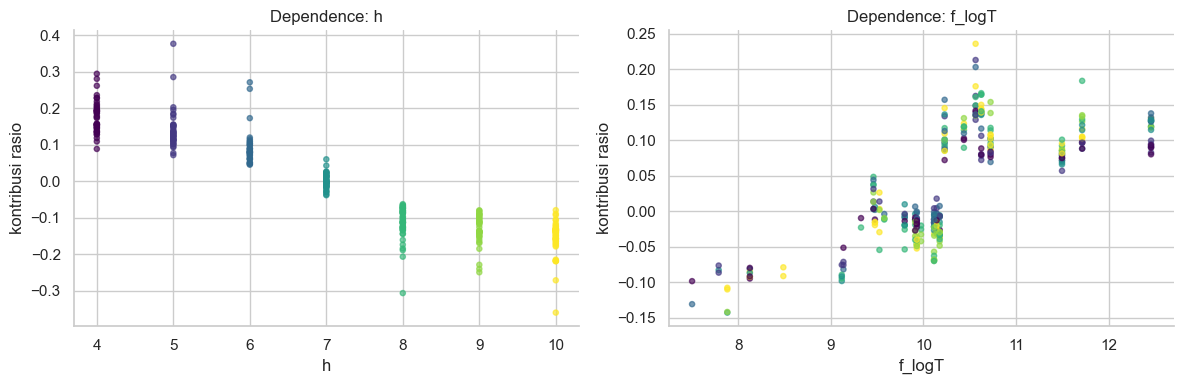

,movie_title,cinema_ids,h,scale,total_ticket
28311,SORE ISTRI DARI MASA DEPAN,5ff7565cdb056b4bdcb43d0ea2b5380d,6,22.0,266.0


,kontribusi_rasio
p3,0.318066
f_logT,0.203092
h,0.172539
fp3,0.160447
sh_trend,0.140465
n_hist,0.134555
log_s,-0.111342
share,-0.103498


In [32]:
if CFG.RUN_MODE == "END_TO_END":
    top_features=importance.head(2).index.tolist()
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,c in zip(axes,top_features):
        j=LFEATS.index(c); ax.scatter(xai_val[c],sv_l1[:,j],c=xai_val.h,cmap='viridis',s=14,alpha=.65)
        ax.set(xlabel=c,ylabel='kontribusi rasio',title=f'Dependence: {c}')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR/'treeshap_dependence.png'); plt.show()
    local_i=int(np.argmax(np.abs(xai_val.total_ticket.values-xai_l1.predict(xai_val[LFEATS])*xai_val.scale.values*xai_val.cal_mult.values)/xai_val.scale.values))
    local=pd.Series(sv_l1[local_i,:-1],index=LFEATS)
    display(xai_val.iloc[[local_i]][['movie_title','cinema_ids','h','scale','total_ticket']])
    display(local.reindex(local.abs().nlargest(8).index).to_frame('kontribusi_rasio'))

#### Insights

> Dependence menunjukkan respons model pada rentang fitur sampel validasi. Mengubah satu fitur dapat menghasilkan kombinasi yang tidak realistis, khususnya rasio pembukaan yang saling terikat.

## Sensitivitas Blend Akhir

Analisis ini memakai model fold 0 dan konteks latihnya. Nilai fitur digeser ke kuartil bawah serta atas konteks, dan respons kedua komponen dibandingkan pada baris validasi yang sama. Analisis ini menilai respons fungsi model; bukan SHAP atau efek kausal.

In [33]:
if CFG.RUN_MODE == "END_TO_END":
    xai_query=xai_val.iloc[:min(28,len(xai_val))].copy()
    xai_context=add_dow(train_part(0),P0,g0)
    probe=[]
    for c in ['sh_trend','cin_dowrel','occ3_r']:
        for q in [.25,.75]:
            z=xai_query.copy(); z[c]=float(xai_context[c].quantile(q))
            l1,p0,Q=predict_lgb_all(xai_fit,z,P0,g0)
            if c=='cin_dowrel':
                z_l=z.copy(); z_l[c]=float(xai_context[c].quantile(q))
                l1=np.clip(np.mean([m.predict(z_l[LFEATS]) for m in xai_fit['l1']],0),0,None)
                p0=np.mean([m.predict_proba(z_l[LZFEATS])[:,1] for m in xai_fit['zc']],0)
                Q=np.mean([np.sort(np.column_stack([m.predict(z_l[LFEATS]) for m in ms]),axis=1) for ms in xai_fit['qm']],0)
            a=((1-CFG.HURDLE_W)*l1+CFG.HURDLE_W*mixture_median(p0,Q,CFG.QS,CFG.LAMBDA))
            b=tabpfn_median(tabpfn_quantiles(xai_context,z),CFG.LAMBDA)
            blend=CFG.WEIGHTS['lgb']*a+CFG.WEIGHTS['tabpfn']*b
            probe.append({'feature':c,'quantile':q,'value':z[c].iloc[0],'LGB_ratio':a.mean(),'TabPFN_ratio':b.mean(),'blend_ratio':blend.mean()})
    display(pd.DataFrame(probe).round(4))
    pd.DataFrame(probe).to_csv(CFG.OUTPUT_DIR/'blend_sensitivity.csv',index=False)

,feature,quantile,value,LGB_ratio,TabPFN_ratio,blend_ratio
0,sh_trend,0.25,0.5455,0.5407,0.4955,0.5046
1,sh_trend,0.75,1.0000,0.5624,0.5334,0.5392
2,cin_dowrel,0.25,-0.3746,0.5654,0.5256,0.5335
3,cin_dowrel,0.75,0.1220,0.5652,0.5485,0.5518
4,occ3_r,0.25,-7.3500,0.5623,0.5209,0.5292
5,occ3_r,0.75,8.7800,0.5623,0.5388,0.5435


#### Insights

> Hasil sensitivitas menjelaskan apakah kedua komponen merespons searah. Kuartil dipilih dari konteks latih; analisis tidak mengubah parameter atau submission final.

---

# Experiment Registry dan Pemilihan Final <a name="11"></a>

---

Registry merangkum keluarga eksperimen yang relevan dengan sistem final. Hasil kecil, negatif, serta asumsi validasi dipertahankan agar alasan pemilihan dapat diperiksa.

## Experiment Registry dan Negative Results

| Keluarga | Pertanyaan | Bukti tersimpan | Keputusan |
|---|---|---|---|
| Baseline median kalender | Apakah skala dan hari saja cukup? | MASE OOF sekitar 0,4002 | Pembanding |
| L1 dan hurdle | Apakah target nol perlu dimodelkan terpisah? | L1 0,3217; hurdle tanpa offset 0,3043 | Dipakai sebagai komponen |
| TabPFN tanpa offset | Apakah distribusi in-context membantu? | MASE OOF sekitar 0,2972 | Pembanding utama |
| Fitur relatif dan profil bioskop | Apakah level pasar dan respons hari dapat dipisahkan? | TW-MASE TabPFN final sekitar 0,3165 | Dipakai |
| Blend final | Bagaimana menjaga respons dua komponen? | MASE 0,2992; TW-MASE 0,3177 | Konfigurasi dikunci |
| Penambahan estimator TabPFN 8 ke 16 | Apakah lebih banyak anggota memberi keuntungan? | TW 0,3165 ke 0,3176; lima fold sedikit memburuk | Ditolak |
| Supervisi durasi tayang | Apakah fitur survival membantu? | TW sekitar 0,3165 ke 0,3181 | Ditolak |
| Konteks umur 3/7/14/21 hari | Apakah konteks lifecycle memperbaiki OOF? | Blend TW 0,3177 ke 0,3161; diagnosis segmen campuran | Tidak masuk konfigurasi acuan |

Angka eksperimen yang tidak dilatih ulang di notebook adalah hasil tersimpan pada log penelitian. Tabel keluaran Bagian 8 dan 9 merupakan hasil run notebook ini.

## Audit Pemilihan dan Batas Klaim

Bobot, offset, dan hyperparameter berasal dari eksperimen berulang pada fold yang sama. Oleh karena itu perbaikan kecil dapat mengandung bias seleksi. Subset OOF rilis Agustus-September disebut diagnosis subset waktu, bukan retrain temporal. Uji skenario sintetis juga bukan validasi target independen.

Pipeline memakai batch pembukaan resmi, termasuk konteks film lain yang tersedia dalam batch. Sistem dipilih untuk mereproduksi konfigurasi v20B yang ditetapkan, dengan public score 0,37755 menurut hasil yang dilaporkan pengguna. Skor private tidak disimpulkan dari skor OOF atau public. Tidak ada panggilan API prediksi, AutoML, atau pengiriman submission pada notebook.

---

# Training Final dan Checkpoint ZIP <a name="12"></a>

---

Model final dibangun ulang menggunakan seluruh sampel latih. Checkpoint disimpan sebagai satu berkas, lalu dikompresi otomatis ke ZIP. Mode ini tidak membaca checkpoint eksperimen atau prediksi yang tersimpan.

## Kalender Lebaran dan Nyepi

Lebaran menggunakan agregat transaksi April 2025 pada klaster yang sama. Porsi slate 2025 dibulatkan menjadi 0,92, dan rasio hari pertama dihitung dari 60.458/79.691 dibagi pertumbuhan relatif Jumbo terhadap pasar. Hari kerja setelah cuti 2026 dipetakan ke hari kerja setelah cuti 2025. Skala Denpasar disesuaikan menggunakan pembukaan resmi 18-20 Maret.

Pada pasangan non-slate Denpasar tanggal 18 Maret, konfigurasi acuan menggunakan koreksi multiplikatif berupa rasio dua prediktor historis, dikali faktor pengerupukan dari pembukaan resmi. Kedua prediktor tersebut dilatih ulang di sel berikut hanya untuk mereproduksi aturan kalender ini; tidak ada ID atau angka submission yang ditanam ke kode.

Analog Lebaran tidak memiliki contoh OOF yang setara karena data latih dimulai setelah hari pertama Idulfitri. Keberhasilan pada OOF reguler tidak membuktikan ketepatan analog tersebut.

In [34]:
if CFG.RUN_MODE == "END_TO_END":
    display(pd.DataFrame({'LEB_RHO':[CFG.LEB_RHO],'LEB_DAY1':[CFG.LEB_DAY1],'PULL_A':[PULL_A],'factor_18_Mar':[f18]}))
    display(pd.Series(work_fac,name='faktor_hari_kerja').to_frame())

,LEB_RHO,LEB_DAY1,PULL_A,factor_18_Mar
0,0.92,0.64,-1.32,0.020074


,faktor_hari_kerja
5,1.049566
6,0.886602
7,0.792263


## Fit Ulang dan Kompresi Otomatis

Sel ini melatih booster utama dan dua prediktor pembanding kalender, membangun konteks per horizon dari sampel latih, lalu menyimpan ZIP. TabPFN memakai konteks tersimpan sebagai representasi terlatih dataset ini; backbone tetap bobot publik yang diunduh.

In [35]:
if CFG.RUN_MODE == "END_TO_END":
    t0=time.time()
    Xall=pd.concat([Xtr,Xlim],ignore_index=True) if CFG.USE_LIMITED else Xtr
    final_lgb=fit_lgb_all(Xall,P_all,g_all)
    legacy_base=fit_legacy(Xall,False)
    legacy_tuned=fit_legacy(Xall,True)
    bundle=checkpoint_bundle(Xall,final_lgb,legacy_base,legacy_tuned)
    created_zip=write_zip(bundle)
    pred=predict_bundle(bundle)
    submission=export_submission(pred)
    print(f'Final training + prediction: {time.time()-t0:.0f} seconds')
    metrics={'MASE':mase(y,oof_final,s),'TW_MASE':float(np.average(np.abs(y-oof_final)/s,weights=TW)),
             'seed':CFG.SEED,'fold_scheme':'base-title random permutation modulo 5'}
    (CFG.OUTPUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
    np.savez_compressed(CFG.OUTPUT_DIR/'oof_predictions.npz',y=y,scale=s,fold=FOLD,blend=oof_final,**COMP)

Saved E:\datsci\joint\joints\temp\nb_final_v20b\output\submission.csv rows 72611 SHA256 5066b2130b7d5b20d250ce342c3342febe7c90fc14da84d00ba28a68fc0ed7b4


,id,total_ticket
0,1,31.109875
1,2,26.368765
2,3,9.794868
3,4,0.000000
4,5,0.119408


Final training + prediction: 536 seconds


## Artifact Contract

| Berkas | Isi |
|---|---|
| `JOINTS_NamaTim_model.zip` | checkpoint terkompresi dan manifest checksum |
| `JOINTS_NamaTim_checkpoint.pkl` | hasil training sebelum kompresi; jalur inferensi menerima ZIP |
| `oof_predictions.npz`, `oof_diagnostics.csv` | prediksi serta diagnosis validasi |
| `fold_scores.csv`, `metrics.json` | evaluasi per fold dan konfigurasi |
| `figures/` | plot EDA, error, dan XAI |
| `submission.csv` | 72.611 baris dengan kolom `id,total_ticket` |

Paket untuk panitia memuat notebook dan ZIP model. Data resmi disediakan terpisah oleh panitia; backbone diunduh dari repositori yang dijelaskan pada referensi.

---

# Inference dari ZIP dan Submission <a name="13"></a>

---

Jalur singkat hanya membutuhkan Initialization lalu bagian ini. `MODEL_ZIP` menunjuk file ZIP yang disediakan tim. Pemeriksaan checksum berlangsung sebelum checkpoint digunakan, kemudian prediksi dihitung ulang dari input resmi.

## Membuka ZIP dan Menjalankan Inferensi

ZIP yang valid merupakan satu-satunya masukan checkpoint. Pada end-to-end sel ini tidak mengulang prediksi; pada mode inferensi sel ini mengekstrak checkpoint, memulihkan konfigurasi, dan menghitung submission.

In [36]:
if CFG.RUN_MODE=='INFERENCE':
    bundle=load_zip(CFG.MODEL_ZIP)
    globals().update(prepare_inputs(bundle))
    LFEATS,LZFEATS=FEATS+DOW_NEW,ZFEATS+DOW_NEW
    TAB_FEATS=TAB_V20+DOW_NEW
    assert LFEATS==bundle['features'] and LZFEATS==bundle['zero_features'] and TAB_FEATS==bundle['tab_features']
    TABPFN_CKPT=tabpfn_path()
    pred=predict_bundle(bundle)
    submission=export_submission(pred)

## Pemeriksaan Keluaran

Tabel komposisi prediksi memeriksa nilai nol dan skala hasil per periode. Jumlah baris, urutan ID, dan rentang prediksi diverifikasi sebelum berkas keluaran disimpan.

In [37]:
if 'submission' in globals():
    seg=pd.Series('normal',index=test.index)
    for name,(a,b) in {'Natal':('2025-12-20','2026-01-04'),'Ramadan':('2026-02-19','2026-03-20'),'Lebaran':('2026-03-21','2026-03-29')}.items():
        seg[test.date_show.between(a,b)]=name
    output_summary=pd.DataFrame({'period':seg,'prediction':pred,'scale':Xte.scale.values})
    display(output_summary.groupby('period').agg(rows=('prediction','size'),mean_ticket=('prediction','mean'),
                  zero_share=('prediction',lambda v:(v==0).mean())).round(4))
    assert len(submission)==len(test) and submission.id.equals(sub.id)

,rows,mean_ticket,zero_share
period,,,
Lebaran,4417,770.0094,0.0000
Natal,5235,462.8266,0.0004
Ramadan,12408,41.9659,0.0446
normal,50551,142.7369,0.0422


#### Insights

> Urutan ID, kelengkapan, nilai finite, dan non-negatif diperiksa di fungsi export. Reproduksi terhadap submission acuan diuji di luar notebook agar file acuan tidak menjadi masukan prediksi.

---

# Kesimpulan dan Referensi <a name="14"></a>

---

Hasil dan batas penerapan dirangkum dari eksperimen serta keluaran yang dapat dihasilkan ulang. Referensi mencantumkan sumber kalender, model pretrained, dan dokumentasi metode.

## What Worked

Rekonstruksi seleksi D3, normalisasi skala-kalender, dan distribusi nol-positif memberi perbaikan besar dibanding baseline median. Fitur relatif minggu rilis serta profil hari bioskop memberi cara eksplisit memisahkan permintaan pasar dari respons lokal.

## What Did Not Work dan Risiko Utama

Menambah estimator TabPFN serta fitur survival tidak membantu pada fold yang sama. Error film breakout tetap besar. OOF per film menguji film baru dalam periode historis, tetapi tidak membuktikan generalisasi ke musim baru. Bobot blend dan kalender adalah keputusan yang dibekukan untuk reproduksi, bukan jaminan skor private.

## Referensi dan Versi Sumber

| Sumber | Versi / tanggal | Peran |
|---|---|---|
| [Data JOINTS x INSPIRE](https://www.kaggle.com/competitions/datajointsxinspire) | paket resmi kompetisi | input utama |
| [TabPFN-3.5, Prior Labs](https://huggingface.co/Prior-Labs/tabpfn_3_5) | revisi `06bf2ba35c80a92a3b9abb436b99cf49e7a0365e` | pretrained tabular |
| [Kode TabPFN](https://github.com/PriorLabs/TabPFN) | paket 9.0.0 | in-context regression |
| [LightGBM](https://lightgbm.readthedocs.io/en/v4.6.0/) | 4.6.0 | L1, klasifier, kuantil, TreeSHAP |
| [SKB Libur 2026](https://setneg.go.id/baca/index/inilah_skb_3_menteri_libur_nasional_dan_cuti_bersama_2026) | 19 September 2025 | cuti bersama, Idulfitri, Nyepi |
| [SKB Libur 2025](https://www.kemenkopmk.go.id/skb-3-menteri-libur-nasional-dan-cuti-bersama-tahun-2025) | 2024 dan revisi 2025 | cuti bersama historis |
| [Kalender pendidikan Jakarta 2025/2026](https://news.detik.com/berita/d-8049756/kalender-pendidikan-semester-ganjil-2025-2026-jakarta-cek-tanggal-pentingnya) | 7 Agustus 2025 | libur sekolah |
| [Kalender pendidikan Jakarta 2024/2025](https://tirto.id/kalender-pendidikan-dki-jakarta-tahun-2024-2025-link-unduh-pdf-g1vR) | 2024 | libur sekolah historis |
| [Pembukaan Jumbo, GoodStats](https://goodstats.id/index.php/article/jumbo-tembus-3-juta-penonton-3600-lebih-penayangan-di-900-layar-indonesia-smhYm) | 14 April 2025 | analog Idulfitri: hari pertama 60.458; kumulatif hari kedua 140.149, sehingga tiket hari kedua 79.691 |

Versi paket aktual dan checksum data ditulis ke manifest checkpoint saat training. Akses referensi diperiksa pada 12 Oktober 2026. Jumlah 79.691 dihitung sebagai selisih kumulatif hari kedua dan hari pertama pada publikasi GoodStats, bukan sebagai angka kumulatif.